# **Exercício 02 — Previsão de Sobrevivência no Titanic**

**Objetivo:** construir e avaliar modelos de Machine Learning para prever se um passageiro do Titanic **Sobreviveu (1)** ou **Não Sobreviveu (0)**, usando os mesmos três modelos da atividade de referência (SGD, Dummy e Random Forest) e avaliando acurácia, precisão, recall, F1-score, matriz de confusão, curva ROC e AUC.

# **1. Observar o Panorama Geral**

Configuração inicial do setup para o notebook.

In [1]:
# Definição de fontes padrão para os gráficos
import matplotlib.pyplot as plt

plt.rc('font', size=14)
plt.rc('axes', labelsize=14, titlesize=14)
plt.rc('legend', fontsize=14)
plt.rc('xtick', labelsize=10)
plt.rc('ytick', labelsize=10)

**Dataset:** Titanic (*Titanic - Machine Learning from Disaster*), um conjunto de dados tabulares com informações demográficas e de viagem (classe do bilhete, sexo, idade, familiares a bordo, tarifa e porto de embarque) de passageiros do RMS Titanic.

**Objetivo:** prever se um determinado passageiro sobreviveu ou não ao naufrágio.

**Tipo de Aprendizado:** Aprendizado Supervisionado (a sobrevivência de cada passageiro do conjunto rotulado é conhecida)

**Tipo de Tarefa:** Classificação Binária (0 = Não Sobreviveu, 1 = Sobreviveu)

**Quantidade de entradas e saídas:** MISO (*Multiple Inputs, Single Output*): vários atributos tabulares de entrada para uma única saída binária

**Formato de aprendizado:** Aprendizado em lote (*Batch Learning*)

**Medida de Desempenho:** Acurácia, Precisão, Recall, F1-Score, Matriz de Confusão, Curva ROC e AUC. Diferentemente do Exercício 01, aqui não há um tipo de erro claramente mais grave: um **falso negativo** é um sobrevivente previsto como não sobrevivente, e um **falso positivo** é o contrário.

**Dicionário de atributos** (nome da coluna no arquivo → significado):

| Coluna | Significado |
|---|---|
| `PassengerId` | Identificador do passageiro |
| `Survived` | Sobrevivência (0 = Não, 1 = Sim) — **alvo** |
| `Pclass` | Classe do bilhete (1 = 1ª, 2 = 2ª, 3 = 3ª), uma representação do status socioeconômico |
| `Name` | Nome do passageiro |
| `Sex` | Sexo |
| `Age` | Idade em anos (fracionária se menor que 1; estimada no formato xx,5) |
| `SibSp` | Número de irmãos / cônjuges a bordo |
| `Parch` | Número de pais / filhos a bordo |
| `Ticket` | Número do bilhete |
| `Fare` | Tarifa paga |
| `Cabin` | Número da cabine |
| `Embarked` | Porto de embarque (C = Cherbourg, Q = Queenstown, S = Southampton) |

# **2. Obtenção dos Dados**

A função abaixo é a da atividade de referência, com **uma adaptação**: o caminho passa a ser `../datasets`. O notebook é executado a partir da pasta `Notebooks/`, e o caminho original (`datasets`) criaria uma pasta `Notebooks/datasets/`. Os dados ficam na pasta `datasets/` da raiz do projeto, que é ignorada pelo git.

In [2]:
from pathlib import Path
import pandas as pd
import tarfile
import urllib.request

# Pasta datasets/ da raiz do projeto (o notebook roda em Notebooks/)
PASTA_DATASETS = Path("../datasets")

def load_titanic_data():
    tarball_path = PASTA_DATASETS / "titanic.tgz"
    if not tarball_path.is_file():
        PASTA_DATASETS.mkdir(parents=True, exist_ok=True)
        url = "https://github.com/ageron/data/raw/main/titanic.tgz"
        urllib.request.urlretrieve(url, tarball_path)
        with tarfile.open(tarball_path) as titanic_tarball:
            titanic_tarball.extractall(path=PASTA_DATASETS)

    train_df = pd.read_csv(PASTA_DATASETS / "titanic" / "train.csv")
    test_df = pd.read_csv(PASTA_DATASETS / "titanic" / "test.csv")
    return pd.concat([train_df, test_df], ignore_index=True)

#  O objetivo é treinar um classificador que possa prever a coluna Survived com base nas outras colunas.

In [3]:
data = load_titanic_data()

# Arquivos disponíveis na pasta de dados
print(sorted(p.name for p in (PASTA_DATASETS / "titanic").iterdir()))

print(f"Formato após o concat (train.csv + test.csv): {data.shape}")
print(f"Passageiros SEM valor em Survived: {data['Survived'].isnull().sum()}")

['test.csv', 'train.csv']
Formato após o concat (train.csv + test.csv): (1309, 12)
Passageiros SEM valor em Survived: 418


O arquivo `test.csv` é o conjunto de submissão da competição do Kaggle e **não possui a coluna `Survived`**: ao concatenar, essas linhas ficam com o alvo vazio. Sem rótulo, elas não servem para treinar nem para avaliar os modelos. Por isso, são mantidos **somente os passageiros com `Survived` conhecido** (os do `train.csv`). A separação de um conjunto de teste próprio é feita na seção 2.3.

In [4]:
# Mantém apenas os passageiros com a sobrevivência conhecida
data = data.dropna(subset=['Survived']).reset_index(drop=True)

print(f"Formato após manter só os passageiros rotulados: {data.shape}")
print(f"Passageiros SEM valor em Survived: {data['Survived'].isnull().sum()}")

Formato após manter só os passageiros rotulados: (891, 12)
Passageiros SEM valor em Survived: 0


In [5]:
# Primeiras linhas do conjunto de dados
data.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0.0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1.0,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1.0,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1.0,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0.0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


**Observações:**

* Os arquivos `train.csv` e `test.csv` foram baixados e extraídos para a pasta `datasets/titanic/` da raiz do projeto.
* Após o `concat` da função de referência, o conjunto tem **1309** passageiros, dos quais **418** (todos do `test.csv`) não têm o valor de `Survived`.
* Mantendo só os passageiros rotulados, restam **891 passageiros e 12 colunas**, que são a base de todo o exercício.
* A coluna `Survived` aparece como `0.0`/`1.0` (número decimal) porque os valores vazios do `concat` forçaram o tipo `float`. A conferência e a conversão do alvo são feitas na próxima seção.

## **2.1. Definição do Alvo**

O enunciado define **Sobreviveu = 1** e **Não Sobreviveu = 0**. Antes de usar o alvo, é preciso conferir quais valores a coluna `Survived` realmente contém e corrigir o tipo (`float`, herdado do `concat`).

In [6]:
# Valores existentes em Survived (incluindo ausentes, se houver)
print(data['Survived'].value_counts(dropna=False).sort_index())
print(f"Tipo original: {data['Survived'].dtype}")

# Converte para inteiro: 0.0 -> 0 e 1.0 -> 1
data['Survived'] = data['Survived'].astype(int)
print(f"Tipo após a conversão: {data['Survived'].dtype}")

Survived
0.0    549
1.0    342
Name: count, dtype: int64
Tipo original: float64
Tipo após a conversão: int64


In [7]:
# Rótulos legíveis para as classes
nomes_classes = {0: 'Não Sobreviveu (0)', 1: 'Sobreviveu (1)'}

serie_y = data['Survived'].map(nomes_classes)

# Mostra quantidade absoluta e relativa lado a lado
distribuicao = pd.DataFrame({
    'Quantidade': serie_y.value_counts(),
    'Porcentagem': serie_y.value_counts(normalize=True).map('{:.2%}'.format)
})
print("Distribuição Detalhada das Classes:")
print(distribuicao)

Distribuição Detalhada das Classes:
                    Quantidade Porcentagem
Survived                                  
Não Sobreviveu (0)         549      61.62%
Sobreviveu (1)             342      38.38%


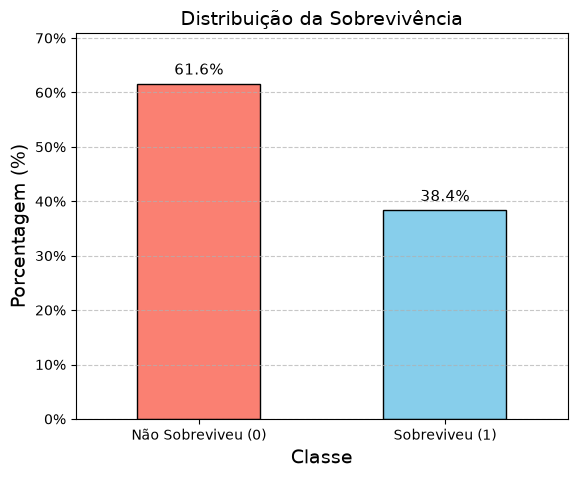

In [8]:
import matplotlib.ticker as mtick

# 1. Calcula as frequências relativas
proporcoes = serie_y.value_counts(normalize=True).sort_index()

plt.figure(figsize=(6, 5))
ax = proporcoes.plot(kind='bar', color=['salmon', 'skyblue'], edgecolor='black')

# 2. Formata o eixo Y para mostrar %
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=0))

# 3. Adiciona o valor em porcentagem no topo de cada barra
for i, valor in enumerate(proporcoes):
    ax.text(i, valor + 0.01, f"{valor:.1%}", ha='center', va='bottom', fontsize=11)

plt.title("Distribuição da Sobrevivência")
plt.xlabel("Classe")
plt.ylabel("Porcentagem (%)")
plt.xticks(rotation=0)
plt.ylim(0, max(proporcoes) * 1.15)
plt.grid(axis='y', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

## **2.2. Descrição dos Dados**

In [9]:
# Tipos de cada coluna e quantidade de valores não nulos
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB


In [10]:
# Valores ausentes por coluna (somente as que têm ausentes)
ausentes = pd.DataFrame({
    'Ausentes': data.isnull().sum(),
    'Porcentagem': (data.isnull().mean()).map('{:.2%}'.format)
})
ausentes[ausentes['Ausentes'] > 0].sort_values('Ausentes', ascending=False)

,Ausentes,Porcentagem
Cabin,687,77.10%
Age,177,19.87%
Embarked,2,0.22%


In [11]:
# Estatísticas descritivas dos atributos numéricos
data[['Pclass', 'Age', 'SibSp', 'Parch', 'Fare']].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
Pclass,891.0,2.31,0.84,1.00,2.00,3.00,3.0,3.00
Age,714.0,29.70,14.53,0.42,20.12,28.00,38.0,80.00
SibSp,891.0,0.52,1.10,0.00,0.00,0.00,1.0,8.00
Parch,891.0,0.38,0.81,0.00,0.00,0.00,0.0,6.00
Fare,891.0,32.20,49.69,0.00,7.91,14.45,31.0,512.33


**Taxa de sobrevivência por grupo**

As taxas abaixo descrevem **associações nos dados** entre um atributo e a sobrevivência. Elas não indicam, sozinhas, a causa da sobrevivência.

In [12]:
# Taxa de sobrevivência (média de Survived) e quantidade de passageiros por Sex e por Pclass
for atributo in ['Sex', 'Pclass']:
    resumo = data.groupby(atributo)['Survived'].agg(Passageiros='count', Taxa_sobrevivencia='mean')
    resumo['Taxa_sobrevivencia'] = resumo['Taxa_sobrevivencia'].map('{:.2%}'.format)
    print(resumo)
    print()

        Passageiros Taxa_sobrevivencia
Sex                                   
female          314             74.20%
male            577             18.89%

        Passageiros Taxa_sobrevivencia
Pclass                                
1               216             62.96%
2               184             47.28%
3               491             24.24%



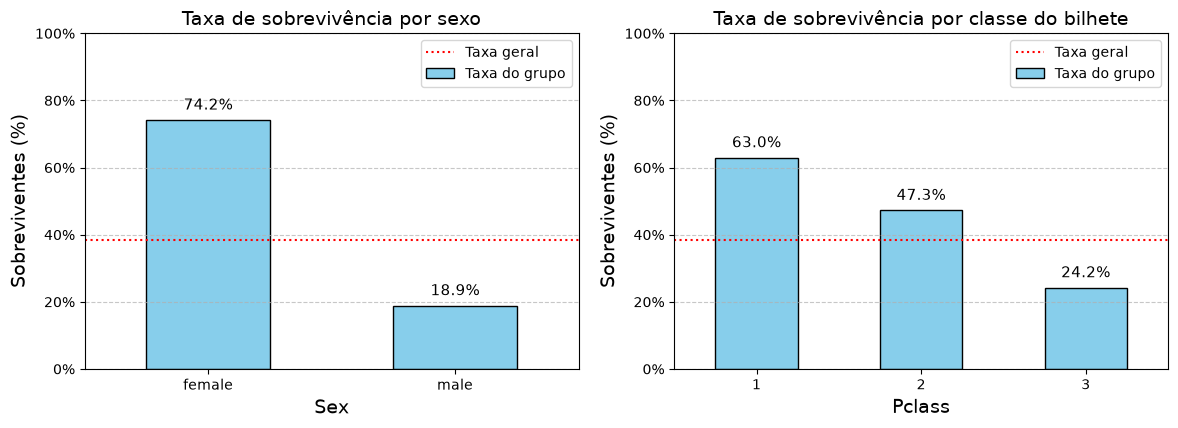

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

for ax, atributo, titulo in zip(axes, ['Sex', 'Pclass'],
                               ['Taxa de sobrevivência por sexo', 'Taxa de sobrevivência por classe do bilhete']):
    taxa = data.groupby(atributo)['Survived'].mean()
    taxa.plot(kind='bar', ax=ax, color='skyblue', edgecolor='black', label='Taxa do grupo')
    ax.set_title(titulo)
    ax.set_xlabel(atributo)
    ax.set_ylabel("Sobreviventes (%)")
    ax.set_ylim(0, 1)
    ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=0))
    ax.tick_params(axis='x', rotation=0)
    ax.grid(axis='y', linestyle='--', alpha=0.7)
    for i, valor in enumerate(taxa):
        ax.text(i, valor + 0.02, f"{valor:.1%}", ha='center', va='bottom', fontsize=11)

# Taxa geral de sobrevivência como referência
for ax in axes:
    ax.axhline(data['Survived'].mean(), color='red', linestyle=':', label='Taxa geral')
    ax.legend(fontsize=10)

plt.tight_layout()
plt.show()

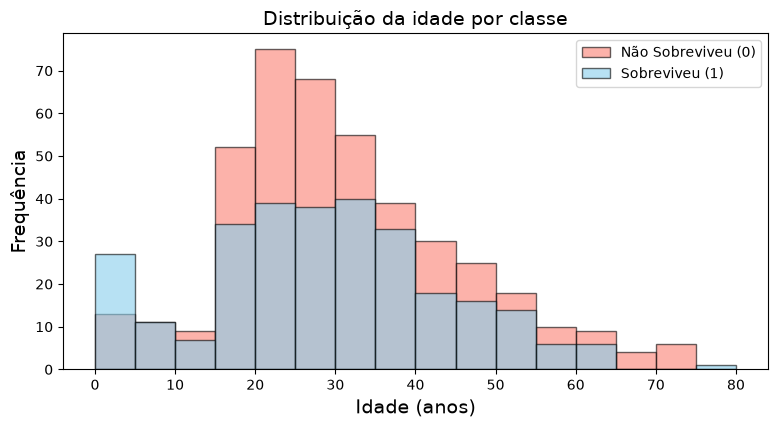

In [14]:
# Distribuição da idade por classe (apenas passageiros com idade conhecida)
# Mesmas faixas de idade (5 anos) para as duas classes, para a comparação ser justa
faixas_idade = range(0, 85, 5)

plt.figure(figsize=(8, 4.5))

for classe, cor in [(0, 'salmon'), (1, 'skyblue')]:
    idades = data.loc[data['Survived'] == classe, 'Age'].dropna()
    plt.hist(idades, bins=faixas_idade, alpha=0.6, color=cor, edgecolor='black', label=nomes_classes[classe])

plt.title("Distribuição da idade por classe")
plt.xlabel("Idade (anos)")
plt.ylabel("Frequência")
plt.legend(fontsize=10)
plt.tight_layout()
plt.show()

**Escolha dos atributos de entrada**

In [15]:
# Colunas candidatas a descarte: quantidade de valores distintos e de ausentes
candidatas_descarte = ['PassengerId', 'Name', 'Ticket', 'Cabin']
pd.DataFrame({
    'Valores distintos': data[candidatas_descarte].nunique(),
    'Ausentes (%)': data[candidatas_descarte].isnull().mean().map('{:.2%}'.format)
})

,Valores distintos,Ausentes (%)
PassengerId,891,0.00%
Name,891,0.00%
Ticket,681,0.00%
Cabin,147,77.10%


In [16]:
# Atributos usados pelos modelos
atributos = ['Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare', 'Embarked']

print(f"Atributos de entrada ({len(atributos)}): {atributos}")
print(f"Colunas descartadas: {candidatas_descarte}")

Atributos de entrada (7): ['Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare', 'Embarked']
Colunas descartadas: ['PassengerId', 'Name', 'Ticket', 'Cabin']


**Observações:**

* **Alvo:** `Survived` contém apenas 0 e 1, já na codificação do enunciado (**1 = Sobreviveu**); foi convertido de `float` para `int`. São **549 não sobreviventes (61,62%)** e **342 sobreviventes (38,38%)**: classes moderadamente desbalanceadas, o que justifica a divisão estratificada e não confiar só na acurácia.
* **Ausentes:** `Cabin` (687; 77,10%), `Age` (177; 19,87%) e `Embarked` (2; 0,22%). `Age` e `Embarked` serão **imputados** no pré-processamento; `Cabin` será descartada.
* **Tipos:** `Sex` e `Embarked` são texto (categóricos) e precisarão de codificação; os demais atributos escolhidos são numéricos. `Fare` vai de 0 a 512,33 (mediana 14,45), e `Age` de 0,42 a 80: escalas diferentes, como no Exercício 01.
* **Associações nos dados:** a taxa de sobrevivência foi de **74,20%** entre mulheres e **18,89%** entre homens, e de **62,96%**, **47,28%** e **24,24%** na 1ª, 2ª e 3ª classes. No histograma, a faixa de 0 a 5 anos tem mais sobreviventes que não sobreviventes, e as faixas de 15 a 35 anos concentram muitos não sobreviventes. São **associações**, não causas.
* **Atributos escolhidos (7):** `Pclass, Sex, Age, SibSp, Parch, Fare, Embarked`. Descartados: `PassengerId` e `Name` (891 valores distintos, um por passageiro: não generalizam), `Ticket` (681 valores distintos, texto livre) e `Cabin` (77,10% ausente).

## **2.3. Separação dos Dados de Treino e Teste**

O conjunto de **teste** (20% dos 891 passageiros rotulados) é separado agora e fica **reservado para a avaliação final**: não será usado para escolher modelos, parâmetros ou limiares. A divisão é **estratificada** (`stratify=y`), para que treino e teste mantenham a mesma proporção de sobreviventes do conjunto completo.

In [17]:
from sklearn.model_selection import train_test_split

# Entradas (somente os atributos escolhidos) e saída
X = data[atributos]
y = data['Survived']

# Divisão COM Estratificação
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)

print(f"Formato do conjunto de treino: {X_train.shape}")
print(f"Formato do conjunto de teste:  {X_test.shape}")

Formato do conjunto de treino: (712, 7)
Formato do conjunto de teste:  (179, 7)


In [18]:
# Quantidade e proporção de cada classe no conjunto completo, no treino e no teste
comparacao_split = pd.DataFrame({
    'Completo': y.map(nomes_classes).value_counts(),
    'Treino': y_train.map(nomes_classes).value_counts(),
    'Teste': y_test.map(nomes_classes).value_counts()
})

print("Quantidade de passageiros por classe:")
print(comparacao_split)

print()
print("Proporção de cada classe:")
print((comparacao_split / comparacao_split.sum()).map('{:.2%}'.format))

Quantidade de passageiros por classe:
                    Completo  Treino  Teste
Survived                                   
Não Sobreviveu (0)       549     439    110
Sobreviveu (1)           342     273     69

Proporção de cada classe:
                   Completo  Treino   Teste
Survived                                   
Não Sobreviveu (0)   61.62%  61.66%  61.45%
Sobreviveu (1)       38.38%  38.34%  38.55%


In [19]:
# Valores ausentes que caíram em cada parte (serão tratados no pré-processamento, aprendendo só com o treino)
pd.DataFrame({
    'Treino': X_train[['Age', 'Embarked']].isnull().sum(),
    'Teste': X_test[['Age', 'Embarked']].isnull().sum()
})

,Treino,Teste
Age,137,40
Embarked,2,0


**Observações:**

* Treino com **712** passageiros (273 sobreviventes) e teste com **179** passageiros (69 sobreviventes), cada um com os 7 atributos escolhidos.
* A estratificação manteve a proporção de sobreviventes praticamente igual nos três conjuntos (38,38% completo, 38,34% treino, 38,55% teste).
* Os valores ausentes ficaram distribuídos entre as partes: `Age` tem 137 ausentes no treino e 40 no teste; os 2 ausentes de `Embarked` caíram no treino. O pré-processamento vai **aprender a mediana e a moda apenas com o treino** e aplicá-las ao teste.
* No teste, cada sobrevivente não identificado reduz o recall em cerca de 1,4 ponto percentual (1/69).

## **2.4. Pré-processamento com `ColumnTransformer`**

Os modelos do Scikit-Learn só trabalham com **números** e **sem valores ausentes**. Os dados do Titanic têm ausentes (`Age`, `Embarked`) e atributos de texto (`Sex`, `Embarked`), por isso cada grupo de colunas recebe um tratamento próprio:

| Grupo | Atributos | Etapa 1 | Etapa 2 |
|---|---|---|---|
| Numéricos | `Pclass, Age, SibSp, Parch, Fare` | Preenche ausentes com a **mediana** (`SimpleImputer`) | **Padroniza** (`StandardScaler`) |
| Categóricos | `Sex, Embarked` | Preenche ausentes com o valor **mais frequente** (`SimpleImputer`) | Cria uma coluna 0/1 por categoria (`OneHotEncoder`) |

O `ColumnTransformer` aplica cada tratamento às suas colunas e junta o resultado. Ele será colocado **dentro do Pipeline** de cada modelo (seção 3), para que medianas, modas, médias e desvios sejam aprendidos **somente com os dados de treino** de cada divisão.

`Pclass` é tratado como **numérico ordinal** (1ª < 2ª < 3ª), preservando a ordem entre as classes.

In [20]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

atributos_numericos = ['Pclass', 'Age', 'SibSp', 'Parch', 'Fare']
atributos_categoricos = ['Sex', 'Embarked']

# Tratamento de cada grupo de colunas
num_pipeline = make_pipeline(SimpleImputer(strategy='median'), StandardScaler())
cat_pipeline = make_pipeline(SimpleImputer(strategy='most_frequent'),
                             OneHotEncoder(handle_unknown='ignore'))

# Junta os dois tratamentos, cada um aplicado às suas colunas
preprocessamento = ColumnTransformer([
    ('num', num_pipeline, atributos_numericos),
    ('cat', cat_pipeline, atributos_categoricos)
])
preprocessamento

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``

**Inspeção do pré-processamento (ajustado somente no treino)**

Para entender o que é aprendido, uma **cópia** do pré-processador é ajustada com `X_train`. Os modelos receberão o `preprocessamento` original dentro dos seus Pipelines, na seção 3.

In [21]:
from sklearn.base import clone

# Cópia ajustada só no treino, apenas para inspeção
prep_inspecao = clone(preprocessamento).fit(X_train)

num_ajustado = prep_inspecao.named_transformers_['num']
cat_ajustado = prep_inspecao.named_transformers_['cat']

# Valores aprendidos no treino para os atributos numéricos
pd.DataFrame({
    'Mediana (imputação)': num_ajustado.named_steps['simpleimputer'].statistics_,
    'Média (padronização)': num_ajustado.named_steps['standardscaler'].mean_,
    'Desvio (padronização)': num_ajustado.named_steps['standardscaler'].scale_
}, index=atributos_numericos).round(3)

,Mediana (imputação),Média (padronização),Desvio (padronização)
Pclass,3.000,2.309,0.833
Age,28.500,29.556,13.016
SibSp,0.000,0.493,1.060
Parch,0.000,0.390,0.838
Fare,14.454,31.820,48.025


In [22]:
# Valores aprendidos no treino para os atributos categóricos
for atributo, moda, categorias in zip(atributos_categoricos,
                                      cat_ajustado.named_steps['simpleimputer'].statistics_,
                                      cat_ajustado.named_steps['onehotencoder'].categories_):
    print(f"{atributo}: moda (imputação) = {moda!r}; categorias = {list(categorias)}")

Sex: moda (imputação) = 'male'; categorias = ['female', 'male']
Embarked: moda (imputação) = 'S'; categorias = ['C', 'Q', 'S']


In [23]:
# Resultado da transformação do treino
X_train_prep = prep_inspecao.transform(X_train)
nomes_colunas_prep = prep_inspecao.get_feature_names_out()

print(f"Tipo do resultado: {type(X_train_prep).__name__}")
print(f"Formato: {X_train.shape} -> {X_train_prep.shape}")
print(f"Valores ausentes após a transformação: {pd.isnull(X_train_prep).sum()}")
print(f"Colunas geradas ({len(nomes_colunas_prep)}): {list(nomes_colunas_prep)}")

Tipo do resultado: ndarray
Formato: (712, 7) -> (712, 10)
Valores ausentes após a transformação: 0
Colunas geradas (10): ['num__Pclass', 'num__Age', 'num__SibSp', 'num__Parch', 'num__Fare', 'cat__Sex_female', 'cat__Sex_male', 'cat__Embarked_C', 'cat__Embarked_Q', 'cat__Embarked_S']


In [24]:
# Exemplo: o primeiro passageiro do treino com idade ausente, antes e depois
posicao = X_train['Age'].isnull().to_numpy().argmax()

print("Antes do pré-processamento:")
print(X_train.iloc[[posicao]].to_string())

print()
print("Depois do pré-processamento:")
print(pd.DataFrame(X_train_prep[[posicao]], columns=nomes_colunas_prep).round(3).to_string())

Antes do pré-processamento:
     Pclass   Sex  Age  SibSp  Parch     Fare Embarked
692       3  male  NaN      0      0  56.4958        S

Depois do pré-processamento:
   num__Pclass  num__Age  num__SibSp  num__Parch  num__Fare  cat__Sex_female  cat__Sex_male  cat__Embarked_C  cat__Embarked_Q  cat__Embarked_S
0         0.83    -0.081      -0.465      -0.466      0.514              0.0            1.0              0.0              0.0              1.0


**Observações:**

* **Aprendido somente no treino:** mediana de `Age` = **28,5** (no conjunto completo era 28,0), mediana de `Fare` = 14,454 e moda de `Embarked` = **'S'**. Médias e desvios da padronização também vêm só do treino.
* A média de `Age` usada na padronização (29,556) é calculada **depois** da imputação, porque o `StandardScaler` vem depois do `SimpleImputer` no pipeline numérico.
* **Resultado:** os 7 atributos viraram **10 colunas numéricas**: 5 numéricas padronizadas e 5 colunas 0/1 do *one-hot* (`Sex`: female/male; `Embarked`: C/Q/S). Não resta nenhum valor ausente.
* **Exemplo:** um passageiro de 3ª classe, sem idade registrada, recebeu a mediana 28,5, que padronizada vale −0,081 (um pouco abaixo da média). `Sex = male` virou `Sex_female = 0` e `Sex_male = 1`; `Embarked = S` virou `Embarked_S = 1`.
* `handle_unknown='ignore'`: se aparecer uma categoria não vista no treino, todas as colunas *one-hot* daquele atributo ficam 0, em vez de gerar erro.
* Esta cópia (`prep_inspecao`) serviu só para inspeção. Na próxima seção, o `preprocessamento` entra **dentro do Pipeline** de cada modelo.

# **3. Treinamento dos Modelos de Classificação Binária**

Os três modelos da atividade de referência são treinados **somente com o conjunto de treino** (`X_train`, `y_train`). O SGD e a Random Forest recebem, **dentro do Pipeline**, uma cópia própria do `preprocessamento` da seção 2.4: ao chamar `fit`, o Pipeline primeiro ajusta o pré-processamento com os dados de treino e depois treina o modelo com os dados transformados.

Os dois modelos reais usam `class_weight='balanced'`, que dá peso maior aos erros da classe minoritária (Sobreviveu) durante o treino:

\begin{equation}
  peso_{classe} = \frac{n_{amostras}}{n_{classes} \times n_{amostras\ da\ classe}}
\end{equation}

In [25]:
import numpy as np
from sklearn.utils.class_weight import compute_class_weight

# Pesos que class_weight='balanced' atribui a cada classe no conjunto de treino
pesos = compute_class_weight(class_weight='balanced', classes=np.array([0, 1]), y=y_train)

for classe, peso in zip([0, 1], pesos):
    print(f"{nomes_classes[classe]}: peso {peso:.3f}")

Não Sobreviveu (0): peso 0.811
Sobreviveu (1): peso 1.304


In [26]:
# Passageiro de exemplo: o primeiro SOBREVIVENTE do treino
indice = np.where(y_train.to_numpy() == 1)[0][0]
passageiro = X_train.iloc[[indice]]

print(f"Posição do exemplo no treino: {indice}")
print(passageiro.to_string())
print(f"Classe real: {nomes_classes[y_train.iloc[indice]]}")

Posição do exemplo no treino: 0
     Pclass   Sex  Age  SibSp  Parch     Fare Embarked
692       3  male  NaN      0      0  56.4958        S
Classe real: Sobreviveu (1)


##  **3.1 Modelo Gradiente Descendente Estocástico (*Stochastic Gradient Descent*)**

O `SGDClassifier` é um **classificador linear**: calcula uma pontuação (*score*) como soma ponderada das 10 colunas geradas pelo pré-processamento. Se a pontuação for maior que 0, prevê **Sobreviveu (1)**; caso contrário, **Não Sobreviveu (0)**. Por depender do gradiente, é **sensível à escala**, e por isso a padronização do pré-processamento é necessária.

In [27]:
#  Classificador Binário Descida de Gradiente Estocástico, com pré-processamento no Pipeline
from sklearn.linear_model import SGDClassifier

sgd_clf = make_pipeline(
    clone(preprocessamento),
    SGDClassifier(class_weight='balanced', random_state=42)
)
sgd_clf.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('columntransformer', ...), ('sgdclassifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](7,)","['Pclass','Sex','Age',...,'Parch','Fare','Embarked']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,7
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remainin

In [28]:
# Previsão para o passageiro de exemplo (o Pipeline aplica o pré-processamento antes de prever)
print(f"Classe prevista (SGD): {nomes_classes[sgd_clf.predict(passageiro)[0]]}")

Classe prevista (SGD): Não Sobreviveu (0)


##  **3.2 Modelo Classificador Bobo (*Dummy Classifier*)**

O `DummyClassifier` é a **linha de base**: com `strategy="most_frequent"`, prevê para todo passageiro a classe mais frequente do treino, sem olhar os atributos. Aqui, essa classe é **Não Sobreviveu (0)**. Por ignorar os atributos, não precisa de pré-processamento.

In [29]:
# Classificador que sempre prevê a classe majoritária
from sklearn.dummy import DummyClassifier

dummy_clf = DummyClassifier(strategy="most_frequent", random_state=42)
dummy_clf.fit(X_train, y_train) # não é necessário pré-processar

,"strategy strategy: {""most_frequent"", ""prior"", ""stratified"", ""uniform"", ""constant""}, default=""prior""Strategy to use to generate predictions.* ""most_frequent"": the `predict` method always returns the most frequent class label in the observed `y` argument passed to `fit`. The `predict_proba` method returns the matching one-hot encoded vector.* ""prior"": the `predict` method always returns the most frequent class label in the observed `y` argument passed to `fit` (like ""most_frequent""). ``predict_proba`` always returns the empirical class distribution of `y` also known as the empirical class prior distribution.* ""stratified"": the `predict_proba` method randomly samples one-hot vectors from a multinomial distribution parametrized by the empirical class prior probabilities. The `predict` method returns the class label which got probability one in the one-hot vector of `predict_proba`. Each sampled row of both methods is therefore independent and identically distributed.* ""uniform"": generates predictions uniformly at random from the list of unique classes observed in `y`, i.e. each class has equal probability.* ""constant"": always predicts a constant label that is provided by the user. This is useful for metrics that evaluate a non-majority class. .. versionchanged:: 0.24 The default value of `strategy` has changed to ""prior"" in version 0.24.",'most_frequent'
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness to generate the predictions when``strategy='stratified'`` or ``strategy='uniform'``.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"constant constant: int or str or array-like of shape (n_outputs,), default=NoneThe explicit constant as predicted by the ""constant"" strategy. Thisparameter is useful only for the ""constant"" strategy.",None
Name,Type,Value
"class_prior_ class_prior_: ndarray of shape (n_classes,) or list of such arraysFrequency of each class observed in `y`. For multioutput classificationproblems, this is computed independently for each output.","ndarray[float64](2,)","[0.62,0.38]"
"classes_ classes_: ndarray of shape (n_classes,) or list of such arraysUnique class labels observed in `y`. For multi-output classificationproblems, this attribute is a list of arrays as each output has anindependent set of possible classes.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X` hasfeature names that are all strings.","ndarray[object](7,)","['Pclass','Sex','Age',...,'Parch','Fare','Embarked']"
n_classes_ n_classes_: int or list of intNumber of label for each output.,int,2
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`.,int,7
n_outputs_ n_outputs_: intNumber of outputs.,int,1
sparse_output_ sparse_output_: boolTrue if the array returned from predict is to be in sparse CSC format.Is automatically set to True if the input `y` is passed in sparseformat.,bool,False


In [30]:
print(f"Classe prevista (Dummy): {nomes_classes[dummy_clf.predict(passageiro)[0]]}")

Classe prevista (Dummy): Não Sobreviveu (0)


##  **3.3 Modelo Floresta Aleatória**

A Floresta Aleatória (*Random Forest*) combina os votos de muitas **árvores de decisão**, cada uma treinada com uma amostra diferente dos dados e dos atributos. Ela não precisa de padronização (cada divisão compara um atributo com um limiar), mas precisa de **números sem ausentes**: por isso também recebe o pré-processamento. A padronização incluída nele não altera as divisões das árvores.

In [31]:
# Classificador por floresta aleatória, com pré-processamento no Pipeline
from sklearn.ensemble import RandomForestClassifier

forest_clf = make_pipeline(
    clone(preprocessamento),
    RandomForestClassifier(class_weight='balanced', random_state=42)
)
forest_clf.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('columntransformer', ...), ('randomforestclassifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](7,)","['Pclass','Sex','Age',...,'Parch','Fare','Embarked']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,7
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all

In [32]:
print(f"Classe prevista (Random Forest): {nomes_classes[forest_clf.predict(passageiro)[0]]}")

Classe prevista (Random Forest): Sobreviveu (1)


**Observações:**

* Os três modelos foram treinados apenas com `X_train` e `y_train`; o conjunto de teste continua reservado.
* `class_weight='balanced'` atribuiu peso **1,304** à classe Sobreviveu e **0,811** à classe Não Sobreviveu: um erro em um sobrevivente pesa cerca de 1,6 vez mais no treino.
* Cada Pipeline tem sua **própria cópia** do pré-processamento (`clone`), ajustada no `fit` com os dados de treino. O `preprocessamento` original continua sem ajuste, como modelo-base.
* **Exemplo:** o primeiro sobrevivente do treino é um passageiro **do sexo masculino, da 3ª classe e sem idade registrada**, um perfil que, nos dados, está associado a baixa sobrevivência (Etapa 2). O SGD e o Dummy previram Não Sobreviveu; a Random Forest previu Sobreviveu.
* Esse passageiro **faz parte do treino**: o acerto da Random Forest pode refletir apenas a memorização de um caso visto, e o erro do SGD mostra um modelo linear seguindo o padrão geral. É **um único exemplo**, que não mede desempenho; a avaliação começa na próxima seção, com validação cruzada.

# **4. Avaliação de Performance**

Cada previsão é comparada com a classe real. No contexto deste exercício (classe positiva = **Sobreviveu**):

| Sigla | Nome | Significado aqui |
|---|---|---|
| **TP** | Verdadeiro Positivo | Sobrevivente previsto como sobrevivente |
| **TN** | Verdadeiro Negativo | Não sobrevivente previsto como não sobrevivente |
| **FP** | Falso Positivo | Não sobrevivente previsto como sobrevivente |
| **FN** | Falso Negativo | Sobrevivente previsto como não sobrevivente |

Diferentemente do Exercício 01, **nenhum dos dois erros é claramente mais grave**: FN e FP têm importância equivalente.

**Acurácia**

Proporção de previsões corretas. É enganosa com classes desbalanceadas: aqui, prever "não sobreviveu" para todos acertaria cerca de 62%.

\begin{equation}
  Acc = \frac{TP + TN}{TP + TN + FP + FN}
\end{equation}

**Precisão**

"De todos os passageiros que o modelo previu como sobreviventes, quantos realmente sobreviveram?"

\begin{equation}
  Precision = \frac{TP}{TP + FP}
\end{equation}

**Recall**

"De todos os sobreviventes reais, quantos o modelo identificou?"

\begin{equation}
  Recall = \frac{TP}{TP + FN}
\end{equation}

**F1-Score**

Média harmônica entre precisão e recall; só é alta quando as duas são altas. Como FN e FP têm importância equivalente neste exercício, o F1 é o critério de equilíbrio adotado.

\begin{equation}
  F1 = 2 \times \frac{Precision \times Recall}{Precision + Recall} = \frac{2TP}{2TP + FP + FN}
\end{equation}

**Curva ROC e AUC**

As métricas acima dependem do **limiar** de decisão. A **curva ROC** mostra o desempenho em **todos os limiares**: para cada limiar, marca a taxa de verdadeiros positivos (TPR, que é o recall) contra a taxa de falsos positivos (FPR):

\begin{equation}
  TPR = \frac{TP}{TP + FN} \qquad FPR = \frac{FP}{FP + TN}
\end{equation}

A **AUC** (*Area Under the Curve*) é a área sob a curva ROC, entre 0 e 1. Ela equivale à probabilidade de o modelo dar uma pontuação maior a um sobrevivente escolhido ao acaso do que a um não sobrevivente escolhido ao acaso. **AUC = 0,5** corresponde a um classificador sem poder de separação (como sortear); **AUC = 1** é a separação perfeita.

## **4.1 Validação Cruzada**

O desempenho é estimado **somente com o conjunto de treino**: o treino é dividido em 5 dobras estratificadas; em cada rodada, o modelo é treinado em 4 dobras e avaliado na dobra restante. Como o pré-processamento está **dentro do Pipeline**, medianas, moda e padronização são reaprendidas em cada rodada só com as 4 dobras de treino.

Precisão e F1 usam `zero_division=0` porque o Dummy nunca prevê Sobreviveu (precisão 0/0). A AUC usa as pontuações dos modelos (`decision_function` no SGD; probabilidade na RF e no Dummy).

In [33]:
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.metrics import make_scorer, precision_score, f1_score

# Validação cruzada estratificada, reutilizada em todas as avaliações no treino
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Métricas desejadas (precisão e F1 valem 0 quando não há previsões positivas)
metricas = {
    'accuracy': 'accuracy',
    'precision': make_scorer(precision_score, zero_division=0),
    'recall': 'recall',
    'f1': make_scorer(f1_score, zero_division=0),
    'roc_auc': 'roc_auc'
}

# Nome de cada métrica para exibição
nomes_metricas = {'accuracy': 'Acurácia', 'precision': 'Precisão', 'recall': 'Recall',
                  'f1': 'F1-Score', 'roc_auc': 'AUC'}

**SGDClassifier**

In [34]:
# Executa a validação cruzada calculando todas as métricas juntas
resultados_sgd = cross_validate(sgd_clf, X_train, y_train, cv=cv, scoring=metricas)

# Exibe a média e o desvio padrão de cada métrica nas 5 dobras
for chave, nome in nomes_metricas.items():
    print(f"{nome:9s} {resultados_sgd['test_' + chave].mean():.2%} ± {resultados_sgd['test_' + chave].std():.2%}")

Acurácia  71.90% ± 4.40%
Precisão  62.78% ± 6.81%
Recall    69.58% ± 10.40%
F1-Score  65.33% ± 5.34%
AUC       78.75% ± 3.76%


**DummyClassifier**

In [35]:
resultados_dummy = cross_validate(dummy_clf, X_train, y_train, cv=cv, scoring=metricas)

for chave, nome in nomes_metricas.items():
    print(f"{nome:9s} {resultados_dummy['test_' + chave].mean():.2%} ± {resultados_dummy['test_' + chave].std():.2%}")

Acurácia  61.66% ± 0.27%
Precisão  0.00% ± 0.00%
Recall    0.00% ± 0.00%
F1-Score  0.00% ± 0.00%
AUC       50.00% ± 0.00%


**RandomForest**

In [36]:
resultados_forest = cross_validate(forest_clf, X_train, y_train, cv=cv, scoring=metricas)

for chave, nome in nomes_metricas.items():
    print(f"{nome:9s} {resultados_forest['test_' + chave].mean():.2%} ± {resultados_forest['test_' + chave].std():.2%}")

Acurácia  78.51% ± 1.45%
Precisão  71.03% ± 3.16%
Recall    74.72% ± 1.45%
F1-Score  72.76% ± 0.98%
AUC       86.31% ± 0.75%


**F1 e AUC em cada dobra**

In [37]:
# F1 e AUC dos modelos reais em cada uma das 5 dobras (mostra a variação entre as divisões)
por_dobra = pd.DataFrame({
    'SGD - F1': resultados_sgd['test_f1'],
    'SGD - AUC': resultados_sgd['test_roc_auc'],
    'RF - F1': resultados_forest['test_f1'],
    'RF - AUC': resultados_forest['test_roc_auc']
}, index=[f"Dobra {i}" for i in range(1, 6)])

por_dobra.map('{:.2%}'.format)

,SGD - F1,SGD - AUC,RF - F1,RF - AUC
Dobra 1,69.64%,81.37%,73.21%,85.30%
Dobra 2,65.35%,72.43%,72.57%,85.57%
Dobra 3,71.43%,83.08%,72.41%,86.58%
Dobra 4,64.18%,80.00%,71.30%,86.82%
Dobra 5,56.07%,76.85%,74.29%,87.27%


**Gráfico dos Resultados de Validação Cruzada**

In [38]:
# Estrutura de dados com a média de cada métrica para cada modelo
resultados_cv = {
    'Dummy Classifier': resultados_dummy,
    'SGD Classifier': resultados_sgd,
    'Random Forest': resultados_forest
}

df_comparacao = pd.DataFrame({
    modelo: {nome: res['test_' + chave].mean() for chave, nome in nomes_metricas.items()}
    for modelo, res in resultados_cv.items()
}).T
df_comparacao.index.name = 'Modelo'

df_comparacao.map('{:.2%}'.format)

,Acurácia,Precisão,Recall,F1-Score,AUC
Modelo,,,,,
Dummy Classifier,61.66%,0.00%,0.00%,0.00%,50.00%
SGD Classifier,71.90%,62.78%,69.58%,65.33%,78.75%
Random Forest,78.51%,71.03%,74.72%,72.76%,86.31%


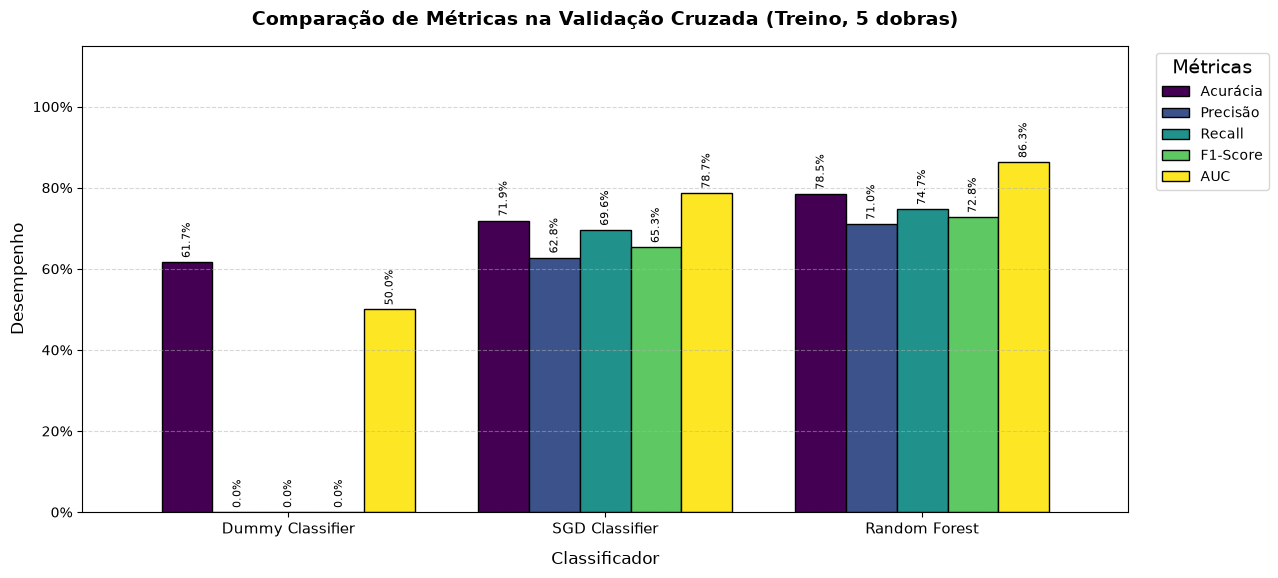

In [39]:
# Configura o tamanho da figura
fig, ax = plt.subplots(figsize=(13, 6))

# Plota o gráfico de barras diretamente do DataFrame
df_comparacao.plot(kind='bar', ax=ax, width=0.8, colormap='viridis', edgecolor='black')

# Estilização do gráfico
plt.title("Comparação de Métricas na Validação Cruzada (Treino, 5 dobras)", fontsize=14, fontweight='bold', pad=15)
plt.xlabel("Classificador", fontsize=12, labelpad=10)
plt.ylabel("Desempenho", fontsize=12)
plt.xticks(rotation=0, fontsize=11)
plt.ylim(0, 1.15)

# Formata o eixo Y para mostrar porcentagem
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=0))
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.legend(title="Métricas", bbox_to_anchor=(1.02, 1), loc='upper left', fontsize=10)

# Adiciona os valores em porcentagem no topo das barras
for container in ax.containers:
    labels = [f"{v * 100:.1f}%" for v in container.datavalues]
    ax.bar_label(container, labels=labels, padding=3, fontsize=8, rotation=90)

plt.tight_layout()
plt.show()

**Observações:**

* **Dummy:** acurácia de 61,66% (a proporção de não sobreviventes no treino), com precisão, recall e F1 iguais a 0 e **AUC = 50%**: sem nenhum poder de separação, como esperado de um modelo que dá a mesma resposta para todos.
* **Random Forest:** acurácia de 78,51%, F1 de 72,76% e **AUC de 86,31%**, com pouca variação entre as dobras (desvio de 0,98 ponto no F1 e de 0,75 ponto na AUC).
* **SGD:** acurácia de 71,90%, F1 de 65,33% e AUC de 78,75%, com **grande variação entre as dobras** (desvio de 10,40 pontos no recall; o F1 vai de 56,07% a 71,43%).
* Na tabela por dobra, a Random Forest teve F1 e AUC **maiores que os do SGD nas 5 dobras**. Diferentemente do Exercício 01, aqui a vantagem de um modelo é consistente entre as divisões.
* Os dois modelos reais superam o Dummy por ampla margem. Mesmo assim, o desempenho é bem menor que no Exercício 01: prever a sobrevivência com estes 7 atributos é uma tarefa mais difícil.
* Estes resultados usam o **limiar padrão** de cada modelo; a AUC não depende do limiar. A próxima seção analisa o *trade-off*, as curvas ROC e o ajuste do limiar pelo F1.

 ### ***Trade-off* da Precisão e Recall, Curvas ROC e Ajuste do Limiar**

Para cada passageiro, o modelo calcula uma **pontuação** (*score*) e a compara com um **limiar**:

* **SGD:** pontuação = `decision_function`; limiar padrão = **0**.
* **Random Forest:** pontuação = probabilidade de Sobreviveu (`predict_proba`); limiar padrão = **0,5**.

**Baixar o limiar** faz o modelo prever mais sobreviventes: os **FN diminuem** (recall sobe) e os **FP aumentam** (precisão cai). Subir o limiar faz o contrário.

As pontuações do treino são obtidas com `cross_val_predict` (o mesmo `cv`): cada passageiro recebe a pontuação de um modelo que **não o viu** no treino. O teste não é usado.

**Pontuações fora da amostra**

In [40]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import precision_recall_curve, roc_curve, roc_auc_score, recall_score

# SGD: pontuação da função de decisão (limiar padrão = 0)
y_scores_sgd = cross_val_predict(sgd_clf, X_train, y_train, cv=cv,
                                 method="decision_function")

# Random Forest: probabilidade da classe Sobreviveu (limiar padrão = 0,5)
y_probas_forest = cross_val_predict(forest_clf, X_train, y_train, cv=cv,
                                    method="predict_proba")
y_scores_forest = y_probas_forest[:, 1]

# Precisão e recall para cada limiar possível
precisions_sgd, recalls_sgd, thresholds_sgd = precision_recall_curve(y_train, y_scores_sgd)
precisions_forest, recalls_forest, thresholds_forest = precision_recall_curve(y_train, y_scores_forest)

print(f"SGD: pontuações de {y_scores_sgd.min():.2f} a {y_scores_sgd.max():.2f}; {len(thresholds_sgd)} limiares avaliados")
print(f"Random Forest: probabilidades de {y_scores_forest.min():.2f} a {y_scores_forest.max():.2f}; {len(thresholds_forest)} limiares avaliados")

SGD: pontuações de -17.91 a 20.51; 681 limiares avaliados
Random Forest: probabilidades de 0.00 a 1.00; 234 limiares avaliados


**Curvas ROC**

Cada ponto da curva corresponde a um limiar: taxa de falsos positivos (FPR) no eixo X e taxa de verdadeiros positivos (TPR = recall) no eixo Y. A diagonal tracejada é o classificador aleatório (AUC = 0,5).

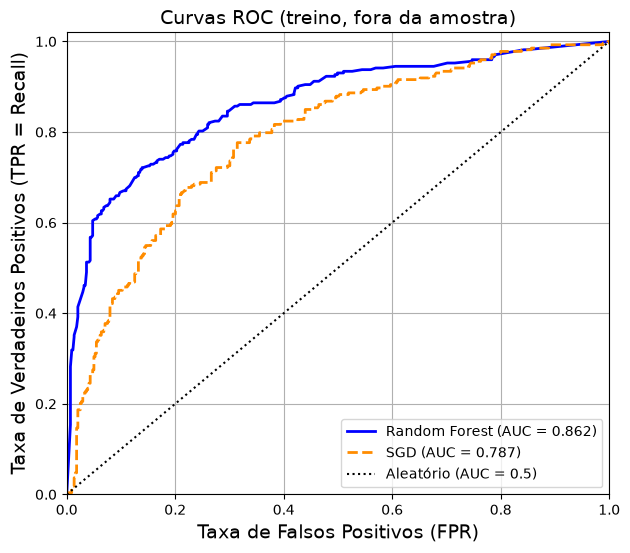

In [41]:
# Pontos da curva ROC (todas as pontuações fora da amostra do treino)
fpr_sgd, tpr_sgd, _ = roc_curve(y_train, y_scores_sgd)
fpr_forest, tpr_forest, _ = roc_curve(y_train, y_scores_forest)

auc_sgd = roc_auc_score(y_train, y_scores_sgd)
auc_forest = roc_auc_score(y_train, y_scores_forest)

plt.figure(figsize=(7, 6))
plt.plot(fpr_forest, tpr_forest, "b-", linewidth=2, label=f"Random Forest (AUC = {auc_forest:.3f})")
plt.plot(fpr_sgd, tpr_sgd, "--", color="darkorange", linewidth=2, label=f"SGD (AUC = {auc_sgd:.3f})")
plt.plot([0, 1], [0, 1], "k:", label="Aleatório (AUC = 0.5)")

plt.title("Curvas ROC (treino, fora da amostra)")
plt.xlabel("Taxa de Falsos Positivos (FPR)")
plt.ylabel("Taxa de Verdadeiros Positivos (TPR = Recall)")
plt.axis([0, 1, 0, 1.02])
plt.grid()
plt.legend(loc="lower right", fontsize=10)
plt.show()

**Escolha do limiar: critério F1**

Como FN e FP têm importância equivalente neste exercício, o limiar escolhido é o que **maximiza o F1** (média harmônica com peso igual para precisão e recall), calculado **somente** com as pontuações fora da amostra do treino:

\begin{equation}
  F1 = \frac{2 \times Precision \times Recall}{Precision + Recall}
\end{equation}

In [42]:
# F1 para cada limiar (o último ponto da curva, recall = 0, não tem limiar associado)
def f1_por_limiar(precisions, recalls):
    p, r = precisions[:-1], recalls[:-1]
    denominador = p + r
    return np.divide(2 * p * r, denominador, out=np.zeros_like(denominador), where=denominador > 0)

f1_sgd = f1_por_limiar(precisions_sgd, recalls_sgd)
f1_forest = f1_por_limiar(precisions_forest, recalls_forest)

# Limiar com o maior F1 em cada modelo
idx_sgd = f1_sgd.argmax()
idx_forest = f1_forest.argmax()
limiar_sgd = thresholds_sgd[idx_sgd]
limiar_forest = thresholds_forest[idx_forest]

print(f"SGD: limiar escolhido = {limiar_sgd:.4f} (padrão = 0)")
print(f"Random Forest: limiar escolhido = {limiar_forest:.4f} (padrão = 0,5)")

SGD: limiar escolhido = -0.8203 (padrão = 0)
Random Forest: limiar escolhido = 0.5954 (padrão = 0,5)


**Curva Precisão × Recall**

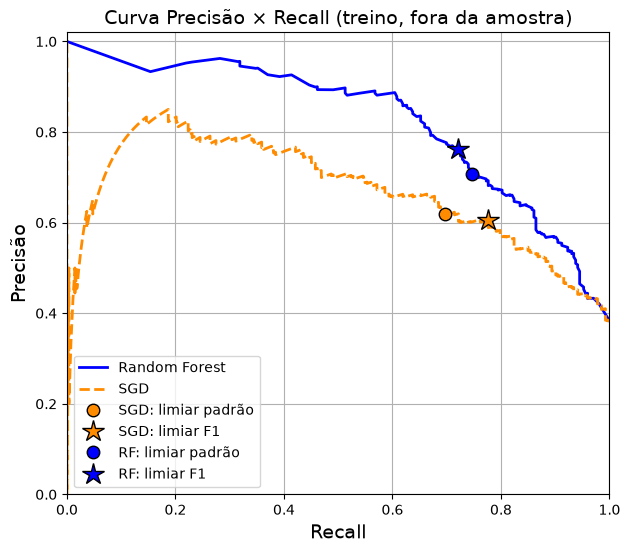

In [43]:
# Pontos no limiar padrão (calculados a partir das previsões no limiar padrão)
pred_padrao_sgd = y_scores_sgd > 0
pred_padrao_forest = y_scores_forest > 0.5

plt.figure(figsize=(7, 6))
plt.plot(recalls_forest, precisions_forest, "b-", linewidth=2, label="Random Forest")
plt.plot(recalls_sgd, precisions_sgd, "--", color="darkorange", linewidth=2, label="SGD")

# Limiar padrão (círculo) e limiar escolhido por F1 (estrela)
plt.plot(recall_score(y_train, pred_padrao_sgd), precision_score(y_train, pred_padrao_sgd), "o",
         color="darkorange", markersize=9, markeredgecolor="k", label="SGD: limiar padrão")
plt.plot(recalls_sgd[idx_sgd], precisions_sgd[idx_sgd], "*", color="darkorange",
         markersize=16, markeredgecolor="k", label="SGD: limiar F1")
plt.plot(recall_score(y_train, pred_padrao_forest), precision_score(y_train, pred_padrao_forest), "bo",
         markersize=9, markeredgecolor="k", label="RF: limiar padrão")
plt.plot(recalls_forest[idx_forest], precisions_forest[idx_forest], "b*",
         markersize=16, markeredgecolor="k", label="RF: limiar F1")

plt.title("Curva Precisão × Recall (treino, fora da amostra)")
plt.xlabel("Recall")
plt.ylabel("Precisão")
plt.axis([0, 1, 0, 1.02])
plt.grid()
plt.legend(loc="lower left", fontsize=10)
plt.show()

**Precisão e Recall em função do limiar**

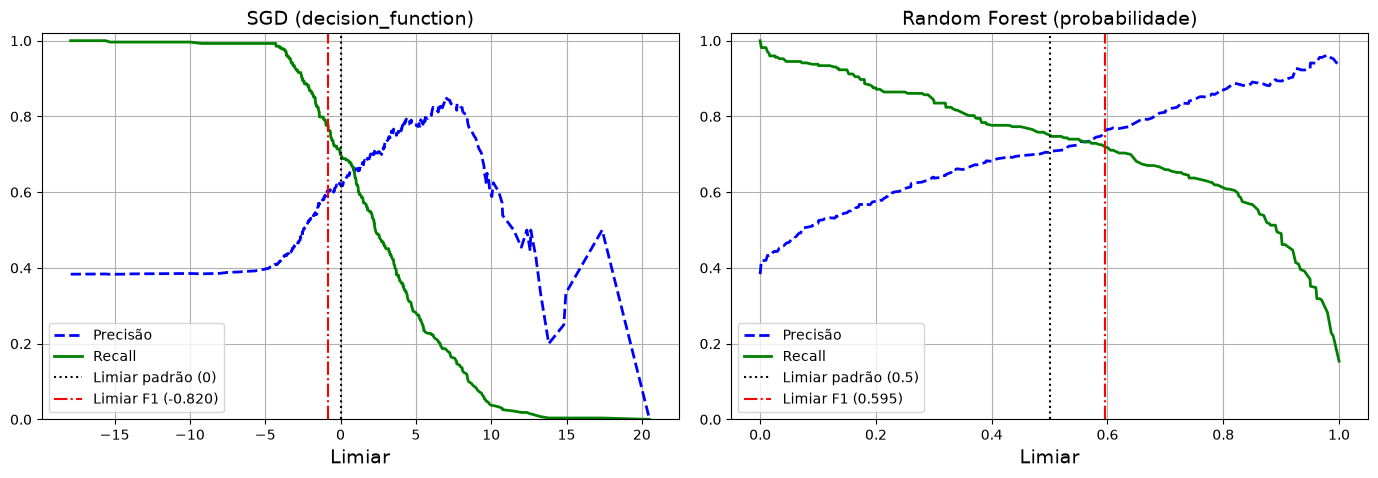

In [44]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

curvas = [
    ("SGD (decision_function)", thresholds_sgd, precisions_sgd, recalls_sgd, 0, limiar_sgd),
    ("Random Forest (probabilidade)", thresholds_forest, precisions_forest, recalls_forest, 0.5, limiar_forest),
]

for ax, (titulo, thresholds, precisions, recalls, padrao, escolhido) in zip(axes, curvas):
    ax.plot(thresholds, precisions[:-1], "b--", linewidth=2, label="Precisão")
    ax.plot(thresholds, recalls[:-1], "g-", linewidth=2, label="Recall")
    ax.axvline(padrao, color="k", linestyle=":", label=f"Limiar padrão ({padrao})")
    ax.axvline(escolhido, color="r", linestyle="-.", label=f"Limiar F1 ({escolhido:.3f})")
    ax.set_title(titulo)
    ax.set_xlabel("Limiar")
    ax.set_ylim(0, 1.02)
    ax.grid()
    ax.legend(loc="lower left", fontsize=10)

plt.tight_layout()
plt.show()

**Comparação: limiar padrão × limiar ajustado (treino, fora da amostra)**

In [45]:
from sklearn.metrics import confusion_matrix, accuracy_score

# Previsões fora da amostra em cada limiar
previsoes_limiar = {
    'SGD - padrão (0)': pred_padrao_sgd,
    f'SGD - F1 ({limiar_sgd:.3f})': y_scores_sgd >= limiar_sgd,
    'Random Forest - padrão (0,5)': pred_padrao_forest,
    f'Random Forest - F1 ({limiar_forest:.3f})': y_scores_forest >= limiar_forest,
}

linhas = []
for nome, y_pred in previsoes_limiar.items():
    tn, fp, fn, tp = confusion_matrix(y_train, y_pred).ravel()
    linhas.append({
        'Modelo - limiar': nome,
        'Acurácia': accuracy_score(y_train, y_pred),
        'Precisão': precision_score(y_train, y_pred),
        'Recall': recall_score(y_train, y_pred),
        'F1-Score': f1_score(y_train, y_pred),
        'FN': fn,
        'FP': fp,
    })

df_limiares = pd.DataFrame(linhas).set_index('Modelo - limiar')

# Exibe as métricas em porcentagem, ao lado das contagens de erros
colunas_pct = ['Acurácia', 'Precisão', 'Recall', 'F1-Score']
df_limiares[colunas_pct].map('{:.2%}'.format).join(df_limiares[['FN', 'FP']])

,Acurácia,Precisão,Recall,F1-Score,FN,FP
Modelo - limiar,,,,,,
SGD - padrão (0),71.91%,61.89%,69.60%,65.52%,83,117
SGD - F1 (-0.820),72.05%,60.57%,77.66%,68.06%,61,138
"Random Forest - padrão (0,5)",78.51%,70.83%,74.73%,72.73%,69,84
Random Forest - F1 (0.595),80.76%,76.36%,72.16%,74.20%,76,61


**Observações:**

* **Curvas ROC:** a curva da Random Forest fica acima da do SGD em quase toda a extensão (AUC fora da amostra de **0,862** contra **0,787**), e as duas ficam bem acima da diagonal do classificador aleatório.
* **SGD:** o limiar que maximiza o F1 é **−0,820**, abaixo do padrão (0). Os FN caíram de **83 para 61** (recall de 69,60% para 77,66%) e os FP subiram de **117 para 138** (precisão de 61,89% para 60,57%). O F1 passou de 65,52% para **68,06%**.
* **Random Forest:** o limiar que maximiza o F1 é **0,595**, **acima** do padrão (0,5). O movimento é o inverso: os FP caíram de **84 para 61** (precisão de 70,83% para 76,36%) e os FN subiram de **69 para 76** (recall de 74,73% para 72,16%). O F1 passou de 72,73% para **74,20%**.
* O critério F1 não favorece um tipo de erro: ele procura o equilíbrio, e por isso pode **baixar** o limiar (SGD) ou **subir** o limiar (RF), conforme o modelo.
* No limiar padrão, os números coincidem com a validação cruzada da seção 4.1 (pequenas diferenças na precisão vêm de aqui as previsões das 5 dobras serem agrupadas antes do cálculo).
* Os limiares foram escolhidos **apenas com previsões fora da amostra do treino**; o efeito real será verificado no teste, sem novos ajustes.

## **4.2 Matriz de Confusão**

A Matriz de Confusão compara as classes reais com as previstas e mostra **onde** cada modelo acerta e erra:

| | Previsto Não Sobreviveu (0) | Previsto Sobreviveu (1) |
|---|---|---|
| **Real Não Sobreviveu (0)** | TN | FP |
| **Real Sobreviveu (1)** | FN | TP |

As previsões do treino são obtidas com `cross_val_predict` (o mesmo `cv`): cada passageiro é classificado por um modelo que **não o viu** no treinamento. Para o SGD e a Random Forest, há uma matriz no **limiar padrão** e outra no **limiar ajustado** (F1) da seção anterior.

In [46]:
from sklearn.metrics import ConfusionMatrixDisplay

# Desenha uma matriz de confusão com classes, eixos e siglas identificados (usada também no teste)
def plot_matriz_confusao(y_real, y_pred, titulo):
    cm = confusion_matrix(y_real, y_pred)
    display = ConfusionMatrixDisplay(confusion_matrix=cm,
                                     display_labels=['Não Sobreviveu (0)', 'Sobreviveu (1)'])
    display.plot(cmap=plt.cm.Blues)

    # Escreve a sigla de cada célula logo acima do valor (mesma cor do número, para manter o contraste)
    siglas = [['TN', 'FP'],
              ['FN', 'TP']]
    for i in range(2):          # i = linha (classe real)
        for j in range(2):      # j = coluna (classe prevista)
            valor = display.text_[i, j]
            valor.set_position((j, i + 0.12))
            display.ax_.text(j, i - 0.18, siglas[i][j], ha='center', va='center',
                             fontsize=13, fontweight='bold', color=valor.get_color())

    plt.title(titulo)
    plt.xlabel("Classe prevista")
    plt.ylabel("Classe real")
    plt.show()
    return cm

**DummyClassifier**

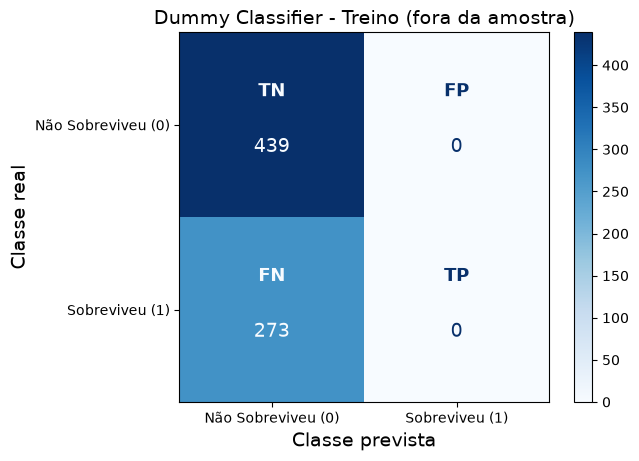

In [47]:
# gera uma previsão para cada passageiro do treino, mas cada previsão é
# feita por um modelo que nunca viu aquele passageiro durante o treinamento.
y_train_pred_dummy = cross_val_predict(dummy_clf, X_train, y_train, cv=cv)

cm_treino_dummy = plot_matriz_confusao(y_train, y_train_pred_dummy,
                                       "Dummy Classifier - Treino (fora da amostra)")

**SGDClassifier — limiar padrão (0)**

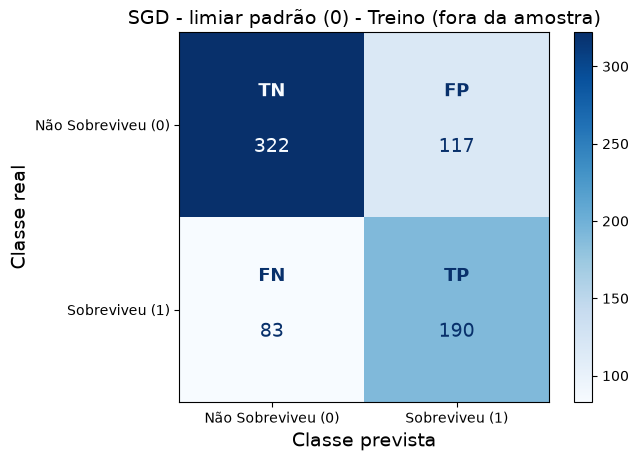

In [48]:
y_train_pred_sgd = cross_val_predict(sgd_clf, X_train, y_train, cv=cv)

cm_treino_sgd = plot_matriz_confusao(y_train, y_train_pred_sgd,
                                     "SGD - limiar padrão (0) - Treino (fora da amostra)")

**SGDClassifier — limiar ajustado (F1)**

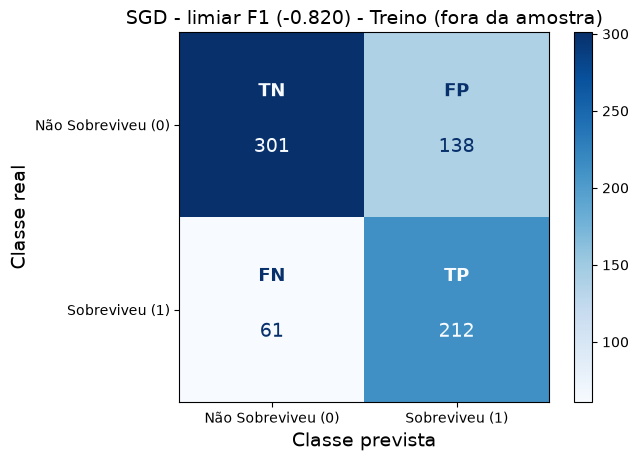

In [49]:
# Aplica o limiar escolhido na seção anterior às pontuações fora da amostra
y_train_pred_sgd_f1 = (y_scores_sgd >= limiar_sgd).astype(int)

cm_treino_sgd_f1 = plot_matriz_confusao(y_train, y_train_pred_sgd_f1,
                                        f"SGD - limiar F1 ({limiar_sgd:.3f}) - Treino (fora da amostra)")

**Random Forest — limiar padrão (0,5)**

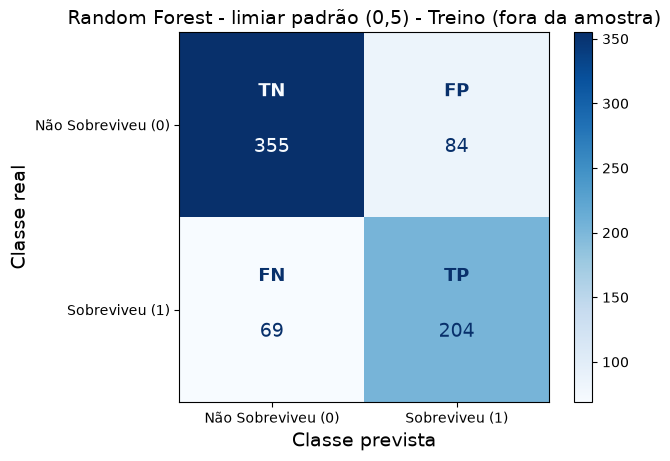

In [50]:
y_train_pred_forest = cross_val_predict(forest_clf, X_train, y_train, cv=cv)

cm_treino_forest = plot_matriz_confusao(y_train, y_train_pred_forest,
                                        "Random Forest - limiar padrão (0,5) - Treino (fora da amostra)")

**Random Forest — limiar ajustado (F1)**

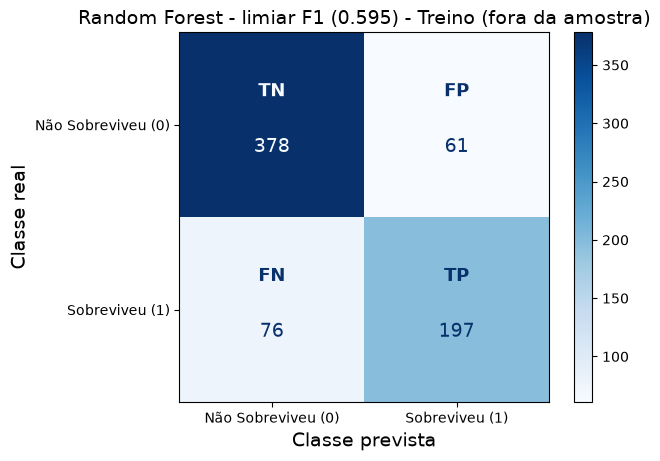

In [51]:
y_train_pred_forest_f1 = (y_scores_forest >= limiar_forest).astype(int)

cm_treino_forest_f1 = plot_matriz_confusao(y_train, y_train_pred_forest_f1,
                                           f"Random Forest - limiar F1 ({limiar_forest:.3f}) - Treino (fora da amostra)")

**Resumo das Matrizes de Confusão no Treino**

In [52]:
# Contagens de cada matriz lado a lado (ravel: TN, FP, FN, TP)
matrizes_treino = {
    'Dummy': cm_treino_dummy,
    'SGD - padrão': cm_treino_sgd,
    'SGD - F1': cm_treino_sgd_f1,
    'Random Forest - padrão': cm_treino_forest,
    'Random Forest - F1': cm_treino_forest_f1,
}

resumo_treino = pd.DataFrame(
    [cm.ravel() for cm in matrizes_treino.values()],
    index=matrizes_treino.keys(),
    columns=['TN', 'FP', 'FN', 'TP']
)
resumo_treino['Erros (FN + FP)'] = resumo_treino['FN'] + resumo_treino['FP']
resumo_treino

,TN,FP,FN,TP,Erros (FN + FP)
Dummy,439,0,273,0,273
SGD - padrão,322,117,83,190,200
SGD - F1,301,138,61,212,199
Random Forest - padrão,355,84,69,204,153
Random Forest - F1,378,61,76,197,137


**Observações:**

* **Dummy:** classifica os 712 passageiros como não sobreviventes; os **273 sobreviventes** viram falsos negativos.
* **SGD:** no limiar padrão, erra 200 passageiros (83 FN e 117 FP). Com o limiar F1, os FN caem para **61** e os FP sobem para **138**: o total de erros fica praticamente igual (199), mas mais equilibrado entre os dois tipos, o que eleva o F1.
* **Random Forest:** no limiar padrão, erra 153 passageiros (69 FN e 84 FP). Com o limiar F1, os FP caem para **61** e os FN sobem para **76**, com **137 erros** no total: o menor número entre todas as matrizes.
* A Random Forest erra menos que o SGD nos dois limiares (153 e 137 contra 200 e 199), coerente com as AUCs da seção anterior.
* Os limiares F1 foram escolhidos com estas mesmas pontuações, então as matrizes "F1" do treino tendem a ser um pouco otimistas; a verificação independente é o teste.

# **5. Teste**

Avaliação final no **conjunto de teste** (179 passageiros, 69 sobreviventes), separado na seção 2.3 e não usado até aqui.

* Os modelos são os treinados na seção 3 com **todo o conjunto de treino**; nada é retreinado. O Pipeline aplica ao teste o pré-processamento **aprendido no treino** (mediana, moda, padronização e categorias).
* Os limiares ajustados (F1) são os escolhidos na seção 4 **somente com o treino**: SGD = `limiar_sgd` e Random Forest = `limiar_forest`.
* A AUC usa as pontuações contínuas e **não depende do limiar**: é a mesma para as versões padrão e F1 de cada modelo.
* Nenhum modelo, parâmetro ou limiar será alterado depois desta avaliação.

In [53]:
from sklearn.metrics import classification_report

nomes_classes_relatorio = ['Não Sobreviveu (0)', 'Sobreviveu (1)']

# Calcula e exibe as métricas de uma previsão no teste (usada para cada modelo e limiar)
def metricas_teste(y_pred, y_score):
    resultado = {
        'Acurácia': accuracy_score(y_test, y_pred),
        'Precisão': precision_score(y_test, y_pred, zero_division=0),
        'Recall': recall_score(y_test, y_pred),
        'F1-Score': f1_score(y_test, y_pred, zero_division=0),
        'AUC': roc_auc_score(y_test, y_score),
    }
    for nome, valor in resultado.items():
        print(f"{nome:9s} {valor:.2%}")
    return resultado

## **5.1. SGDClassifier**

**Limiar padrão (0)**

In [54]:
print("="*45)
print(f"     TESTE: SGD CLASSIFIER - LIMIAR PADRÃO")
print("="*45)

# Pontuação e predição (o Pipeline aplica o pré-processamento aprendido no treino)
y_scores_teste_sgd = sgd_clf.decision_function(X_test)
y_pred_sgd = sgd_clf.predict(X_test)

# Métricas detalhadas por classe
print(classification_report(y_test, y_pred_sgd, target_names=nomes_classes_relatorio))

# Resumo
teste_sgd = metricas_teste(y_pred_sgd, y_scores_teste_sgd)

     TESTE: SGD CLASSIFIER - LIMIAR PADRÃO
                    precision    recall  f1-score   support

Não Sobreviveu (0)       0.80      0.89      0.84       110
    Sobreviveu (1)       0.79      0.64      0.70        69

          accuracy                           0.79       179
         macro avg       0.79      0.76      0.77       179
      weighted avg       0.79      0.79      0.79       179

Acurácia  79.33%
Precisão  78.57%
Recall    63.77%
F1-Score  70.40%
AUC       83.70%


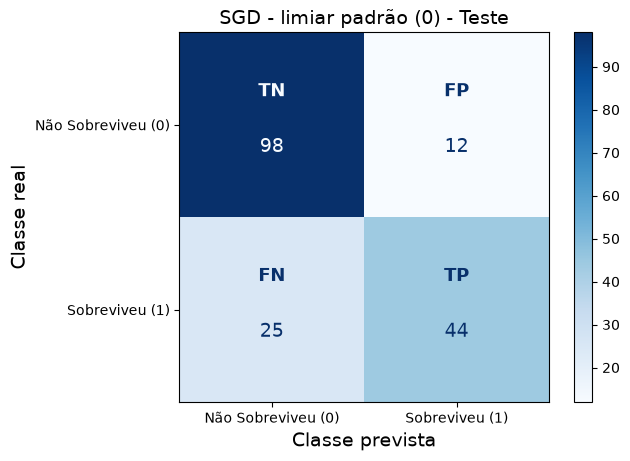

In [55]:
cm_teste_sgd = plot_matriz_confusao(y_test, y_pred_sgd, "SGD - limiar padrão (0) - Teste")

**Limiar ajustado (F1)**

In [56]:
print("="*45)
print(f"     TESTE: SGD CLASSIFIER - LIMIAR F1 ({limiar_sgd:.3f})")
print("="*45)

# Aplica o limiar escolhido no treino às pontuações do teste
y_pred_sgd_f1 = (y_scores_teste_sgd >= limiar_sgd).astype(int)

print(classification_report(y_test, y_pred_sgd_f1, target_names=nomes_classes_relatorio))

teste_sgd_f1 = metricas_teste(y_pred_sgd_f1, y_scores_teste_sgd)

     TESTE: SGD CLASSIFIER - LIMIAR F1 (-0.820)
                    precision    recall  f1-score   support

Não Sobreviveu (0)       0.82      0.78      0.80       110
    Sobreviveu (1)       0.68      0.72      0.70        69

          accuracy                           0.76       179
         macro avg       0.75      0.75      0.75       179
      weighted avg       0.76      0.76      0.76       179

Acurácia  75.98%
Precisão  67.57%
Recall    72.46%
F1-Score  69.93%
AUC       83.70%


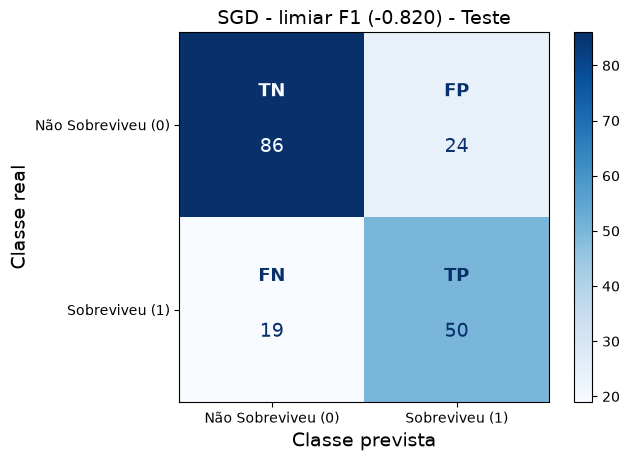

In [57]:
cm_teste_sgd_f1 = plot_matriz_confusao(y_test, y_pred_sgd_f1, f"SGD - limiar F1 ({limiar_sgd:.3f}) - Teste")

## **5.2. DummyClassifier**

In [58]:
print("="*45)
print(f"     TESTE: DUMMY CLASSIFIER")
print("="*45)

# Predição e "pontuação" (a mesma probabilidade para todos os passageiros)
y_pred_dummy = dummy_clf.predict(X_test)
y_scores_teste_dummy = dummy_clf.predict_proba(X_test)[:, 1]

print(classification_report(y_test, y_pred_dummy, target_names=nomes_classes_relatorio, zero_division=0))

teste_dummy = metricas_teste(y_pred_dummy, y_scores_teste_dummy)

     TESTE: DUMMY CLASSIFIER
                    precision    recall  f1-score   support

Não Sobreviveu (0)       0.61      1.00      0.76       110
    Sobreviveu (1)       0.00      0.00      0.00        69

          accuracy                           0.61       179
         macro avg       0.31      0.50      0.38       179
      weighted avg       0.38      0.61      0.47       179

Acurácia  61.45%
Precisão  0.00%
Recall    0.00%
F1-Score  0.00%
AUC       50.00%


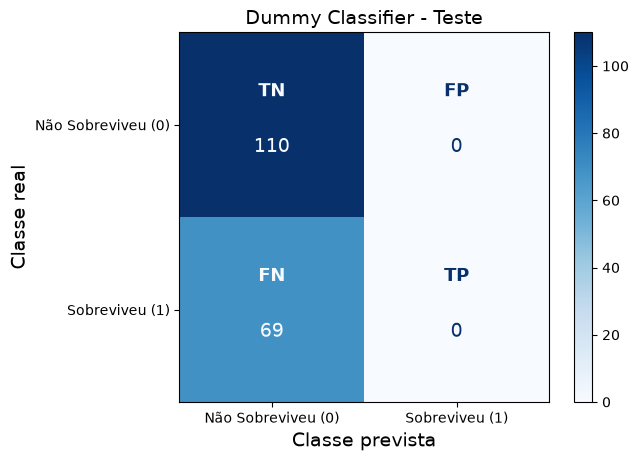

In [59]:
cm_teste_dummy = plot_matriz_confusao(y_test, y_pred_dummy, "Dummy Classifier - Teste")

## **5.3. Random Forest**

**Limiar padrão (0,5)**

In [60]:
print("="*45)
print(f"     TESTE: RANDOM FOREST - LIMIAR PADRÃO")
print("="*45)

# Probabilidade de Sobreviveu e predição
y_scores_teste_forest = forest_clf.predict_proba(X_test)[:, 1]
y_pred_forest = forest_clf.predict(X_test)

print(classification_report(y_test, y_pred_forest, target_names=nomes_classes_relatorio))

teste_forest = metricas_teste(y_pred_forest, y_scores_teste_forest)

     TESTE: RANDOM FOREST - LIMIAR PADRÃO
                    precision    recall  f1-score   support

Não Sobreviveu (0)       0.83      0.86      0.85       110
    Sobreviveu (1)       0.77      0.72      0.75        69

          accuracy                           0.81       179
         macro avg       0.80      0.79      0.80       179
      weighted avg       0.81      0.81      0.81       179

Acurácia  81.01%
Precisão  76.92%
Recall    72.46%
F1-Score  74.63%
AUC       83.04%


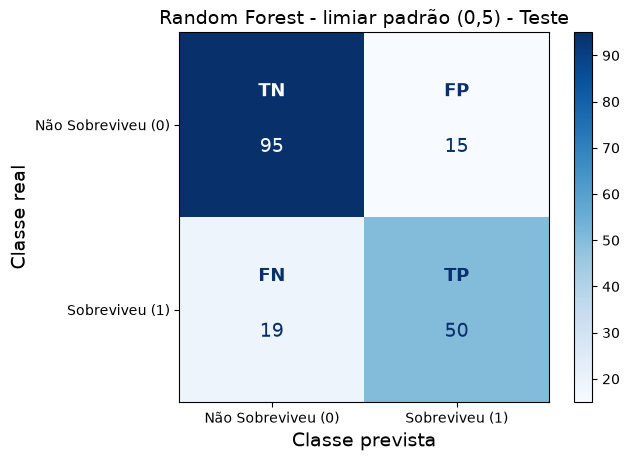

In [61]:
cm_teste_forest = plot_matriz_confusao(y_test, y_pred_forest, "Random Forest - limiar padrão (0,5) - Teste")

**Limiar ajustado (F1)**

In [62]:
print("="*45)
print(f"     TESTE: RANDOM FOREST - LIMIAR F1 ({limiar_forest:.3f})")
print("="*45)

# Aplica o limiar escolhido no treino às probabilidades do teste
y_pred_forest_f1 = (y_scores_teste_forest >= limiar_forest).astype(int)

print(classification_report(y_test, y_pred_forest_f1, target_names=nomes_classes_relatorio))

teste_forest_f1 = metricas_teste(y_pred_forest_f1, y_scores_teste_forest)

     TESTE: RANDOM FOREST - LIMIAR F1 (0.595)
                    precision    recall  f1-score   support

Não Sobreviveu (0)       0.83      0.89      0.86       110
    Sobreviveu (1)       0.80      0.71      0.75        69

          accuracy                           0.82       179
         macro avg       0.82      0.80      0.81       179
      weighted avg       0.82      0.82      0.82       179



Acurácia  82.12%
Precisão  80.33%
Recall    71.01%
F1-Score  75.38%
AUC       83.04%


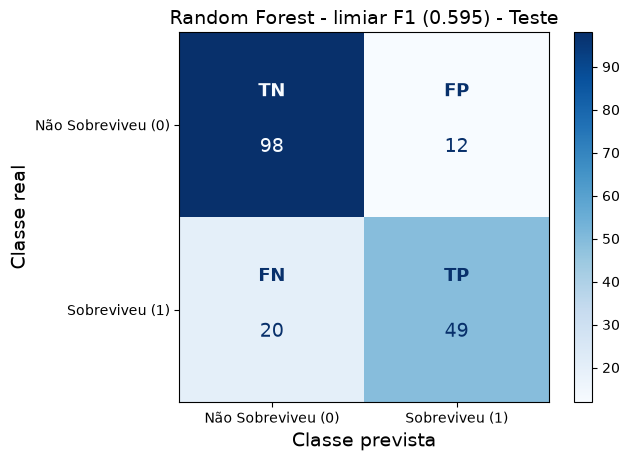

In [63]:
cm_teste_forest_f1 = plot_matriz_confusao(y_test, y_pred_forest_f1, f"Random Forest - limiar F1 ({limiar_forest:.3f}) - Teste")

## **5.4. Curvas ROC no Teste**

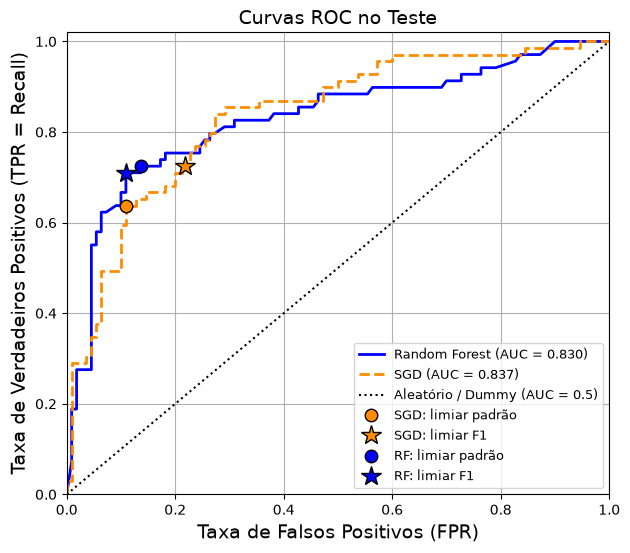

In [64]:
# Pontos da curva ROC no teste (a curva não depende do limiar)
fpr_teste_sgd, tpr_teste_sgd, _ = roc_curve(y_test, y_scores_teste_sgd)
fpr_teste_forest, tpr_teste_forest, _ = roc_curve(y_test, y_scores_teste_forest)

plt.figure(figsize=(7, 6))
plt.plot(fpr_teste_forest, tpr_teste_forest, "b-", linewidth=2,
         label=f"Random Forest (AUC = {teste_forest['AUC']:.3f})")
plt.plot(fpr_teste_sgd, tpr_teste_sgd, "--", color="darkorange", linewidth=2,
         label=f"SGD (AUC = {teste_sgd['AUC']:.3f})")
plt.plot([0, 1], [0, 1], "k:", label="Aleatório / Dummy (AUC = 0.5)")

# Posição de cada limiar sobre a curva (padrão = círculo; F1 = estrela)
for y_pred, marcador, cor, rotulo in [
        (y_pred_sgd, 'o', 'darkorange', 'SGD: limiar padrão'),
        (y_pred_sgd_f1, '*', 'darkorange', 'SGD: limiar F1'),
        (y_pred_forest, 'o', 'blue', 'RF: limiar padrão'),
        (y_pred_forest_f1, '*', 'blue', 'RF: limiar F1')]:
    tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
    plt.plot(fp / (fp + tn), tp / (tp + fn), marcador, color=cor, markeredgecolor='k',
             markersize=15 if marcador == '*' else 9, label=rotulo)

plt.title("Curvas ROC no Teste")
plt.xlabel("Taxa de Falsos Positivos (FPR)")
plt.ylabel("Taxa de Verdadeiros Positivos (TPR = Recall)")
plt.axis([0, 1, 0, 1.02])
plt.grid()
plt.legend(loc="lower right", fontsize=9)
plt.show()

## **5.5. Resumo do Teste**

In [65]:
# Métricas e contagens de erros de todos os modelos e limiares no teste
resultados_teste = {
    'Dummy Classifier': (teste_dummy, cm_teste_dummy),
    'SGD - padrão': (teste_sgd, cm_teste_sgd),
    'SGD - F1': (teste_sgd_f1, cm_teste_sgd_f1),
    'Random Forest - padrão': (teste_forest, cm_teste_forest),
    'Random Forest - F1': (teste_forest_f1, cm_teste_forest_f1),
}

df_teste = pd.DataFrame({modelo: metricas for modelo, (metricas, cm) in resultados_teste.items()}).T
df_teste[['TN', 'FP', 'FN', 'TP']] = [cm.ravel() for metricas, cm in resultados_teste.values()]
df_teste['Erros (FN + FP)'] = df_teste['FN'] + df_teste['FP']
df_teste.index.name = 'Modelo'

colunas_pct = ['Acurácia', 'Precisão', 'Recall', 'F1-Score', 'AUC']
colunas_cont = ['TN', 'FP', 'FN', 'TP', 'Erros (FN + FP)']
df_teste[colunas_pct].map('{:.2%}'.format).join(df_teste[colunas_cont].astype(int))

,Acurácia,Precisão,Recall,F1-Score,AUC,TN,FP,FN,TP,Erros (FN + FP)
Modelo,,,,,,,,,,
Dummy Classifier,61.45%,0.00%,0.00%,0.00%,50.00%,110,0,69,0,69
SGD - padrão,79.33%,78.57%,63.77%,70.40%,83.70%,98,12,25,44,37
SGD - F1,75.98%,67.57%,72.46%,69.93%,83.70%,86,24,19,50,43
Random Forest - padrão,81.01%,76.92%,72.46%,74.63%,83.04%,95,15,19,50,34
Random Forest - F1,82.12%,80.33%,71.01%,75.38%,83.04%,98,12,20,49,32


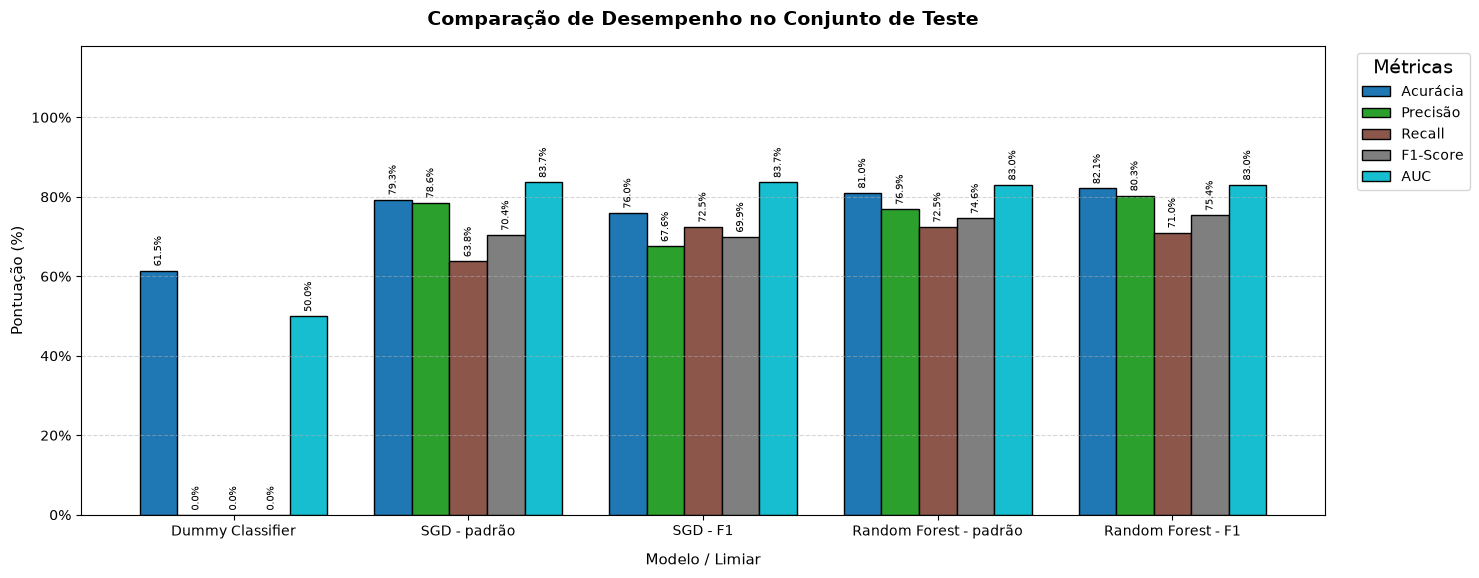

In [66]:
# Configurações do Gráfico (métricas do enunciado)
fig, ax = plt.subplots(figsize=(15, 6))

df_teste[colunas_pct].plot(
    kind="bar", ax=ax, width=0.8, colormap="tab10", edgecolor="black"
)

# Estilização
plt.title("Comparação de Desempenho no Conjunto de Teste", fontsize=14, fontweight="bold", pad=15)
plt.xlabel("Modelo / Limiar", fontsize=11, labelpad=10)
plt.ylabel("Pontuação (%)", fontsize=11)
plt.xticks(rotation=0, fontsize=10)
plt.ylim(0, 1.18)
plt.grid(axis="y", linestyle="--", alpha=0.5)

# Formata o eixo Y em Porcentagem
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=0))

# Adiciona o valor exato em cima de cada barra
for container in ax.containers:
    labels = [f"{v * 100:.1f}%" for v in container.datavalues]
    ax.bar_label(container, labels=labels, padding=3, fontsize=7, rotation=90)

plt.legend(title="Métricas", bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=10)
plt.tight_layout()
plt.show()

**Observações:**

* **Dummy:** acurácia de 61,45% (a proporção de não sobreviventes no teste), **69 falsos negativos** (nenhum sobrevivente identificado) e AUC de 50%.
* **Random Forest com limiar F1** teve o melhor resultado nas métricas que dependem do limiar: acurácia de **82,12%**, precisão de **80,33%**, F1 de **75,38%** e o menor total de erros (**32**: 12 FP e 20 FN). Em relação ao limiar padrão, o ajuste trocou 3 FP por 1 FN, como no treino.
* **SGD:** no limiar padrão, F1 de 70,40%. Com o limiar F1, o recall subiu de 63,77% para 72,46% (+6 sobreviventes identificados), mas os FP dobraram (12 → 24) e o F1 caiu levemente para 69,93%: **no teste, o ajuste não melhorou o F1 do SGD**.
* **AUC no teste:** SGD **83,70%** e Random Forest **83,04%**, valores próximos, com as curvas ROC se cruzando várias vezes. No treino (validação cruzada), a Random Forest tinha AUC claramente maior (86,31% × 78,75%). No teste, o SGD foi melhor do que na validação cruzada e a Random Forest foi um pouco pior.
* Com 179 passageiros (69 sobreviventes), cada sobrevivente vale cerca de 1,4 ponto de recall; as diferenças entre os modelos no teste são de poucos passageiros.
* Estes resultados são definitivos para o exercício: nenhum modelo, parâmetro ou limiar foi alterado depois desta avaliação.

# **6. Comparação Final e Conclusão**

A tabela abaixo coloca lado a lado, para cada modelo e limiar:

* **Treino (validação cruzada):** previsões e pontuações fora da amostra das seções 4.1 a 4.2 (712 passageiros, 273 sobreviventes);
* **Teste:** avaliação final da seção 5 (179 passageiros, 69 sobreviventes).

Nas duas colunas, cada passageiro foi avaliado por um modelo que não o viu no treinamento.

In [67]:
# Pontuação fora da amostra do Dummy no treino (a mesma para todos os passageiros)
y_scores_dummy = cross_val_predict(dummy_clf, X_train, y_train, cv=cv, method="predict_proba")[:, 1]

# (previsões no treino, pontuações no treino, previsões no teste, pontuações no teste)
previsoes_finais = {
    'Dummy': (y_train_pred_dummy, y_scores_dummy, y_pred_dummy, y_scores_teste_dummy),
    'SGD - padrão': (y_train_pred_sgd, y_scores_sgd, y_pred_sgd, y_scores_teste_sgd),
    'SGD - F1': (y_train_pred_sgd_f1, y_scores_sgd, y_pred_sgd_f1, y_scores_teste_sgd),
    'Random Forest - padrão': (y_train_pred_forest, y_scores_forest, y_pred_forest, y_scores_teste_forest),
    'Random Forest - F1': (y_train_pred_forest_f1, y_scores_forest, y_pred_forest_f1, y_scores_teste_forest),
}

linhas = []
for modelo, (pred_treino, score_treino, pred_teste, score_teste) in previsoes_finais.items():
    for conjunto, y_real, y_pred, y_score in [('Treino (validação cruzada)', y_train, pred_treino, score_treino),
                                              ('Teste', y_test, pred_teste, score_teste)]:
        linhas.append({
            'Modelo': modelo,
            'Conjunto': conjunto,
            'Acurácia': accuracy_score(y_real, y_pred),
            'Precisão': precision_score(y_real, y_pred, zero_division=0),
            'Recall': recall_score(y_real, y_pred),
            'F1-Score': f1_score(y_real, y_pred, zero_division=0),
            'AUC': roc_auc_score(y_real, y_score),
            'FN': ((y_real == 1) & (y_pred == 0)).sum(),
            'FP': ((y_real == 0) & (y_pred == 1)).sum(),
            'Sobreviventes': (y_real == 1).sum(),
        })

df_final = pd.DataFrame(linhas).set_index(['Modelo', 'Conjunto'])

colunas_pct = ['Acurácia', 'Precisão', 'Recall', 'F1-Score', 'AUC']
df_final[colunas_pct].map('{:.2%}'.format).join(df_final[['FN', 'FP', 'Sobreviventes']])

Acurácia Precisão  Recall  \
Modelo                 Conjunto                                               
Dummy                  Treino (validação cruzada)   61.66%    0.00%   0.00%   
                       Teste                        61.45%    0.00%   0.00%   
SGD - padrão           Treino (validação cruzada)   71.91%   61.89%  69.60%   
                       Teste                        79.33%   78.57%  63.77%   
SGD - F1               Treino (validação cruzada)   72.05%   60.57%  77.66%   
                       Teste                        75.98%   67.57%  72.46%   
Random Forest - padrão Treino (validação cruzada)   78.51%   70.83%  74.73%   
                       Teste                        81.01%   76.92%  72.46%   
Random Forest - F1     Treino (validação cruzada)   80.76%   76.36%  72.16%   
                       Teste                        82.12%   80.33%  71.01%   

                                                  F1-Score     AUC   FN   FP  \
Modelo                 Conjunto                                                
Dummy                  Treino (validação cruzada)    0.00%  50.00%  273    0   
                       Teste                         0.00%  50.00%   69    0   
SGD - padrão           Treino (validação cruzada)   65.52%  78.68%   83  117   
                       Teste                        70.40%  83.70%   25   12   
SGD - F1               Treino (validação cruzada)   68.06%  78.68%   61  138   
                       Teste                        69.93%  83.70%   19   24   
Random Forest - padrão Treino (validação cruzada)   72.73%  86.23%   69   84   
                       Teste                        74.63%  83.04%   19   15   
Random Forest - F1     Treino (validação cruzada)   74.20%  86.23%   76   61   
                       Teste                        75.38%  83.04%   20   12   

                                                   Sobreviventes  
Modelo                 Conjunto                                   
Dummy                  Treino (validação cruzada)            273  
                       Teste                                  69  
SGD - padrão           Treino (validação cruzada)            273  
                       Teste                                  69  
SGD - F1               Treino (validação cruzada)            273  
                       Teste                                  69  
Random Forest - padrão Treino (validação cruzada)            273  
                       Teste                                  69  
Random Forest - F1     Treino (validação cruzada)            273  
                       Teste                                  69

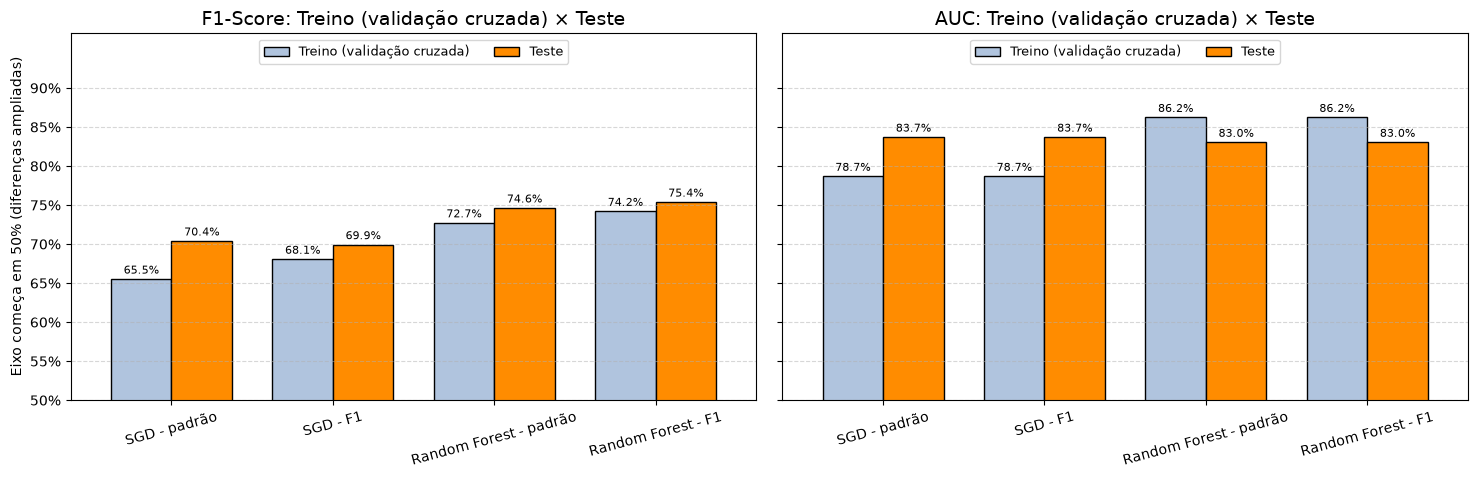

In [68]:
# F1 e AUC no treino (validação cruzada) e no teste, para os modelos reais
modelos_reais = ['SGD - padrão', 'SGD - F1', 'Random Forest - padrão', 'Random Forest - F1']

fig, axes = plt.subplots(1, 2, figsize=(15, 5), sharey=True)

for ax, metrica in zip(axes, ['F1-Score', 'AUC']):
    tabela = df_final[metrica].unstack('Conjunto').loc[modelos_reais,
                                                       ['Treino (validação cruzada)', 'Teste']]
    tabela.plot(kind='bar', ax=ax, width=0.75, color=['lightsteelblue', 'darkorange'], edgecolor='black')
    ax.set_title(f"{metrica}: Treino (validação cruzada) × Teste")
    ax.set_xlabel("")
    ax.set_ylim(0.5, 0.97)
    ax.set_yticks(np.arange(0.50, 0.901, 0.05))
    ax.set_ylabel("Eixo começa em 50% (diferenças ampliadas)", fontsize=10)
    ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=0))
    ax.tick_params(axis='x', rotation=15)
    ax.grid(axis='y', linestyle='--', alpha=0.5)
    ax.legend(loc='upper center', ncol=2, fontsize=9)
    for container in ax.containers:
        ax.bar_label(container, labels=[f"{v * 100:.1f}%" for v in container.datavalues],
                     padding=2, fontsize=8)

plt.tight_layout()
plt.show()

## **6.1. Interpretação dos Resultados**

1. **Linha de base.** O Dummy obteve cerca de 61% de acurácia no treino e no teste sem identificar nenhum sobrevivente (recall 0%; 273 e 69 falsos negativos) e AUC de 50%. A **acurácia sozinha é enganosa** também neste problema.

2. **Os modelos reais aprenderam.** SGD e Random Forest identificaram entre 44 e 50 dos 69 sobreviventes do teste, com F1 entre 69,93% e 75,38% e AUC acima de 83%.

3. **Random Forest: desempenho estável.** O F1 foi parecido no treino e no teste (72,73% → 74,63% no limiar padrão; 74,20% → 75,38% no limiar F1). A AUC caiu de 86,23% para 83,04%. Na validação cruzada, ela superou o SGD em F1 e AUC nas 5 dobras.

4. **SGD: desempenho instável.** O SGD foi bem melhor no teste do que na validação cruzada (F1 65,52% → 70,40%; AUC 78,68% → 83,70%). Isso é coerente com a grande variação que ele já mostrava entre as dobras (F1 de 56% a 71%). No teste, sua AUC ficou praticamente igual à da Random Forest, mas um único teste de 179 passageiros não basta para concluir que os dois se equivalem.

5. **Ajuste do limiar (F1).** Na Random Forest, o limiar 0,595 trocou falsos positivos por menos falsos negativos e **melhorou o F1 no treino e no teste**. No SGD, o limiar −0,820 melhorou o F1 no treino, mas **não no teste** (69,93% contra 70,40%), porque os falsos positivos dobraram. O ganho do ajuste em dados novos depende de onde caem as pontuações desses dados.

6. **Qual configuração escolher?** A **Random Forest com limiar F1** teve o melhor F1 (75,38%), a maior acurácia (82,12%) e precisão (80,33%) e o menor número de erros (32) no teste, além de ter sido a mais consistente na validação cruzada. As diferenças para as demais configurações no teste são de poucos passageiros.

7. **Associações nos dados.** A análise exploratória mostrou forte associação da sobrevivência com o sexo e a classe do bilhete. Os modelos usam essas associações para prever, mas os resultados **não explicam causas**.

## **6.2. Conclusão**

O exercício previu a sobrevivência de passageiros do Titanic (**Sobreviveu = 1**, **Não Sobreviveu = 0**) com os três modelos da atividade de referência. Foram usados apenas os 891 passageiros rotulados, com 7 atributos. Valores ausentes e atributos de texto foram tratados por um `ColumnTransformer` **dentro do Pipeline**, e o teste estratificado foi usado uma única vez.

* SGD e Random Forest superaram amplamente a linha de base, com F1 entre 70% e 75% e AUC acima de 83% no teste, enquanto o Dummy não identificou nenhum sobrevivente.
* As curvas ROC mostraram boa capacidade de separação dos dois modelos. Na validação cruzada, a Random Forest foi consistentemente superior; no teste, os dois ficaram próximos em AUC.
* O ajuste do limiar pelo F1, escolhido apenas com o treino, melhorou a Random Forest no treino e no teste, mas não se confirmou no teste para o SGD.
* A configuração mais equilibrada foi a **Random Forest com limiar F1** (F1 de 75,38% e acurácia de 82,12% no teste).

**Limitações:** conjunto pequeno (891 passageiros; 69 sobreviventes no teste), um único conjunto de teste, hiperparâmetros padrão, imputação simples (mediana/moda), nenhuma engenharia de atributos (por exemplo, o título no nome) e dados históricos de um único evento.

**Estes resultados são de um exercício acadêmico. As relações encontradas são associações nos dados, não relações de causa.**